# What It Costs To Raise A Child Alone In Virginia

**Virginia Datathon 2026 — the story, told in order.**

This notebook is the narrative. It asks, in sequence: who earns what, who inside that group carries
the most, what it costs where they live, what help arrives, and what is left over.

The full derivation of every locality figure — margins of error, validation against published state
totals, definitional tests — lives in `va_single_parent_affordability.ipynb`. This notebook builds the
story on top of that work and adds the chapters that make it a story rather than a finding.

**A note on language.** Nothing here is abbreviated. Agencies, programmes and surveys are written out
in full every time, because a reader should never have to decode an acronym to follow an argument.

**A note on who "she" is.** Where a calculation uses the income of mothers raising children alone, it
says so. Where it is about all single parents, it says that. Roughly 73 percent of these families are
headed by a mother and 27 percent by a father, and their situations are different enough that merging
them hides the finding.

**Sources.** United States Census Bureau, American Community Survey 2020–2024 five-year estimates,
fetched live. Tax and benefit amounts computed with PolicyEngine, an open-source microsimulation model
of the American tax and benefit system. Childcare prices from the United States Department of Labor.
Transportation costs from the Center for Neighborhood Technology. Household budgets from United For
ALICE.

## Chapter 1 — The income ladder

Before asking whether single parents can afford to live in Virginia, it is worth asking a simpler
question: how much do they earn compared with everyone else?

The United States Census Bureau publishes median family income split by the kind of family — married
couples, a father raising children alone, a mother raising children alone — and separately for
families with and without children under eighteen. That one table tells most of the story.

In [1]:
import io, json, os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

YEAR, DATASET = 2024, "acs/acs5"
BASE = f"https://api.census.gov/data/{YEAR}/{DATASET}"
VIRGINIA = "51"
OUTDIR = Path("single_parent_affordability"); OUTDIR.mkdir(exist_ok=True)
FIGDIR = OUTDIR / "figures"; FIGDIR.mkdir(exist_ok=True)

load_dotenv()
CENSUS_API_KEY = (os.environ.get("CENSUS_API_KEY") or "").strip()
assert CENSUS_API_KEY, "CENSUS_API_KEY not found in environment or .env"

# ---- Shared visual system (identical to the derivation notebook) ----
SURFACE = "#fcfcfb"
INK, INK_2, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, NO_DATA = "#e1e0d9", "#c3c2b7", "#e1e0d9"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#0d366b"]
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED, "axes.edgecolor": AXIS, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.linewidth": 0.8, "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})

def census(variables, geography="state:51", inside=None):
    params = {"get": ",".join(variables), "for": geography, "key": CENSUS_API_KEY}
    if inside:
        params["in"] = inside
    response = requests.get(BASE, params=params, timeout=120)
    response.raise_for_status()
    payload = response.json()
    frame = pd.DataFrame(payload[1:], columns=payload[0])
    for column in variables:
        if column != "NAME":
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame

# Census table B19126: median family income by family type by presence of own children.
LADDER = {
    "B19126_003E": ("Married couple", "with children"),
    "B19126_004E": ("Married couple", "no children"),
    "B19126_007E": ("Father raising children alone", "with children"),
    "B19126_008E": ("Father raising children alone", "no children"),
    "B19126_010E": ("Mother raising children alone", "with children"),
    "B19126_011E": ("Mother raising children alone", "no children"),
}
state = census(list(LADDER) + ["B19126_001E"]).iloc[0]

ladder = pd.DataFrame(
    [{"household": h, "children": c, "median_income": state[v]} for v, (h, c) in LADDER.items()]
).pivot(index="household", columns="children", values="median_income")
ladder = ladder.loc[["Married couple", "Father raising children alone",
                     "Mother raising children alone"]]
ladder["change_with_children"] = ladder["with children"] - ladder["no children"]
ladder["percent_change"] = ladder["change_with_children"] / ladder["no children"] * 100

print(f"Median income for ALL Virginia families: ${state['B19126_001E']:,.0f}")
print()
print("Median family income, Virginia, 2020-2024:")
display(ladder.round(0))

married = ladder.loc["Married couple", "with children"]
for household in ["Father raising children alone", "Mother raising children alone"]:
    value = ladder.loc[household, "with children"]
    print(f"  {household:<32} ${value:>8,.0f}  "
          f"= {value / married * 100:>4.0f} cents per married-couple dollar")

Median income for ALL Virginia families: $115,213

Median family income, Virginia, 2020-2024:


children,no children,with children,change_with_children,percent_change
household,,,,
Married couple,127321,150318,22997,18.0
Father raising children alone,91110,65940,-25170,-28.0
Mother raising children alone,71351,44383,-26968,-38.0


  Father raising children alone    $  65,940  =   44 cents per married-couple dollar
  Mother raising children alone    $  44,383  =   30 cents per married-couple dollar


### What that table says

Three household types, raising children, in the same state.

Then look at the final column, which is where the story is. Compare each household type **with**
children against the **same** household type **without** children:

- For a married couple, having children goes with **higher** income. Two earners, prime working
  years, and the children are affordable.
- For a father raising children alone, income is **lower**.
- For a mother raising children alone, it is lower **again**, and by the largest margin.

So the finding is not that single parents earn less than married couples, which anyone would guess.
It is that **children are associated with more income for couples and less income for lone parents —
and the penalty is largest for mothers.**

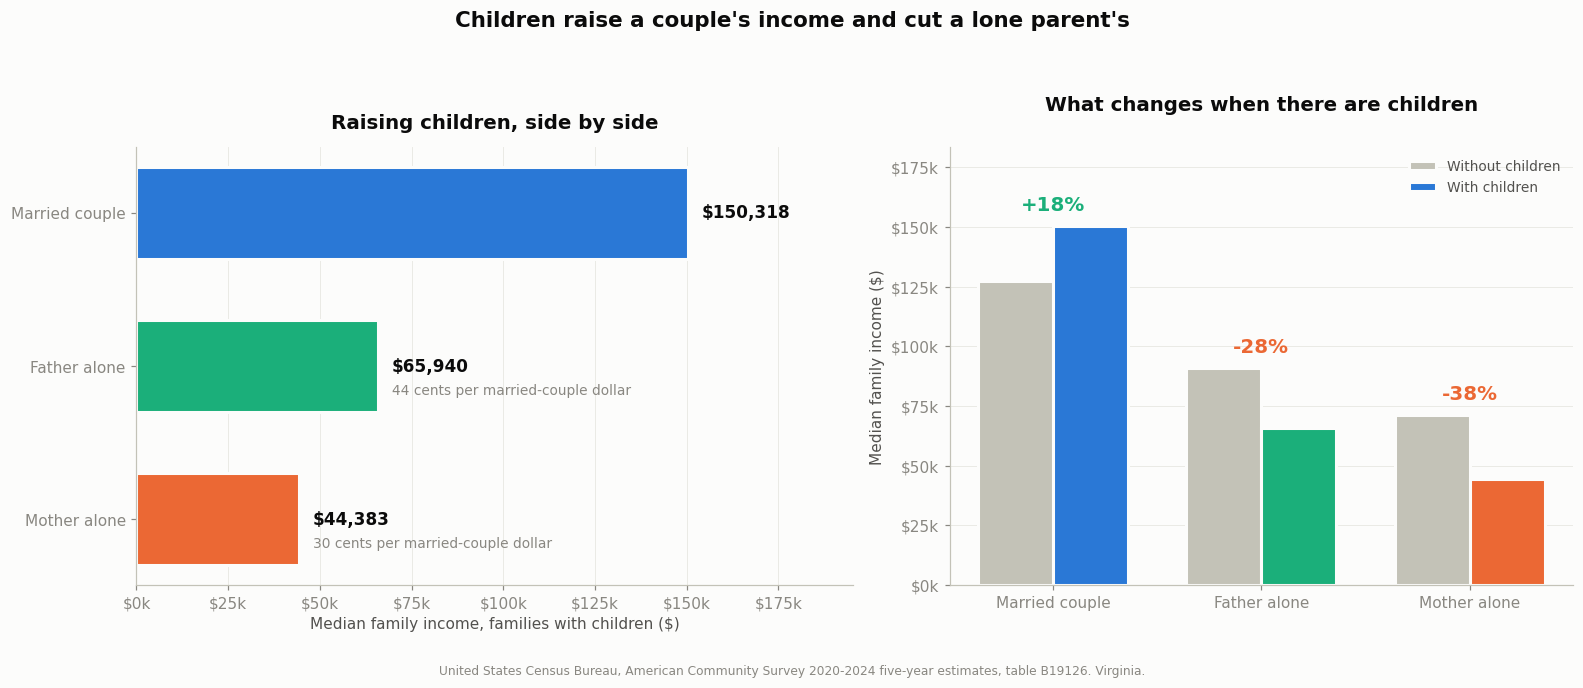

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), gridspec_kw={"width_ratios": [1.15, 1]})

order = ["Married couple", "Father raising children alone", "Mother raising children alone"]
short = ["Married couple", "Father alone", "Mother alone"]
y = np.arange(len(order))
with_children = [ladder.loc[h, "with children"] for h in order]

bars = axes[0].barh(y, with_children, height=0.6, color=[CAT[0], CAT[2], CAT[1]],
                    edgecolor=SURFACE, linewidth=2)
for i, value in enumerate(with_children):
    axes[0].annotate(f"${value:,.0f}", (value, i), xytext=(9, 0), textcoords="offset points",
                     va="center", fontsize=11, fontweight="bold", color=INK)
    share = value / with_children[0] * 100
    if i:
        axes[0].annotate(f"{share:.0f} cents per married-couple dollar", (value, i),
                         xytext=(9, -16), textcoords="offset points", va="center",
                         fontsize=9, color=INK_MUTED)
axes[0].set_yticks(y, short)
axes[0].invert_yaxis()
axes[0].set_xlabel("Median family income, families with children ($)")
axes[0].set_title("Raising children, side by side", pad=12)
axes[0].xaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
axes[0].grid(axis="x", alpha=0.7); axes[0].set_axisbelow(True); axes[0].margins(x=0.30)

width = 0.36
x = np.arange(len(order))
no_children = [ladder.loc[h, "no children"] for h in order]
axes[1].bar(x - width/2, no_children, width, color=AXIS, edgecolor=SURFACE, linewidth=2,
            label="Without children")
axes[1].bar(x + width/2, with_children, width, color=[CAT[0], CAT[2], CAT[1]],
            edgecolor=SURFACE, linewidth=2, label="With children")
for i, h in enumerate(order):
    change = ladder.loc[h, "change_with_children"]
    pct = ladder.loc[h, "percent_change"]
    colour = CAT[2] if change > 0 else CAT[1]
    axes[1].annotate(f"{'+' if change > 0 else ''}{pct:.0f}%",
                     (i, max(no_children[i], with_children[i])), xytext=(0, 10),
                     textcoords="offset points", ha="center", fontsize=13,
                     fontweight="bold", color=colour)
axes[1].set_xticks(x, short)
axes[1].set_ylabel("Median family income ($)")
axes[1].set_title("What changes when there are children", pad=24)
axes[1].yaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
axes[1].grid(axis="y", alpha=0.7); axes[1].set_axisbelow(True); axes[1].margins(y=0.22)
axes[1].legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper right")

fig.suptitle("Children raise a couple's income and cut a lone parent's",
             fontsize=14, fontweight="bold", color=INK, y=1.0)
fig.text(0.5, -0.04, "United States Census Bureau, American Community Survey 2020-2024 "
         "five-year estimates, table B19126. Virginia.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGDIR / "s01_income_ladder.png", bbox_inches="tight")
plt.show()

## Chapter 2 — Gender splits the group almost in half

"Single parent" is one phrase covering two very different situations. Virginia has about 196,000
families headed by a mother raising children alone and about 71,000 headed by a father. Before going
further it is worth seeing how differently the two halves are placed.

In [3]:
# Counts, from Census table B11003; poverty, from Census table B17010.
COUNTS = {"B11003_010E": "father_families", "B11003_016E": "mother_families"}
POVERTY = {"B17010_011E": "father_below", "B17010_031E": "father_above",
           "B17010_017E": "mother_below", "B17010_037E": "mother_above"}
INCOME = {"B19126_007E": "father_income", "B19126_010E": "mother_income"}

row = census(list(COUNTS) + list(POVERTY) + list(INCOME)).iloc[0].rename(
    {**COUNTS, **POVERTY, **INCOME})

father_rate = row.father_below / (row.father_below + row.father_above) * 100
mother_rate = row.mother_below / (row.mother_below + row.mother_above) * 100

summary = pd.DataFrame({
    "Father raising children alone": [row.father_families, row.father_income, father_rate],
    "Mother raising children alone": [row.mother_families, row.mother_income, mother_rate],
}, index=["Families", "Median income ($)", "Share below the poverty line (%)"])
print("Virginia, 2020-2024:")
display(summary.round(1))
print(f"  mothers are {row.mother_families / (row.mother_families + row.father_families) * 100:.0f}% "
      f"of single-parent families")
print(f"  a mother earns {row.mother_income / row.father_income * 100:.0f} cents "
      f"per father dollar")
print(f"  and is {mother_rate / father_rate:.1f} times as likely to be below the poverty line")

# The same comparison inside each locality, where rents and childcare prices are identical.
locality = census(["NAME"] + list(POVERTY), geography="county:*", inside=f"state:{VIRGINIA}")
locality = locality.rename(columns=POVERTY)
locality["locality"] = locality["NAME"].str.replace(", Virginia", "", regex=False)
for sex in ("father", "mother"):
    universe = locality[f"{sex}_below"] + locality[f"{sex}_above"]
    locality[f"{sex}_rate"] = np.where(universe > 0, locality[f"{sex}_below"] / universe * 100, np.nan)
locality["gap"] = locality["mother_rate"] - locality["father_rate"]
locality["families"] = (locality["father_below"] + locality["father_above"]
                        + locality["mother_below"] + locality["mother_above"])

father_universe = locality["father_below"] + locality["father_above"]
solid = locality.loc[(locality["families"] >= 500) & (father_universe >= 100)
                     & locality["gap"].notna()]
print(f"\nIn {int((solid['gap'] > 0).sum())} of {len(solid)} larger localities the rate is higher "
      f"for mothers than for fathers.")
print("Widest gaps inside a single locality, where rents and childcare prices are the same:")
display(solid.nlargest(8, "gap")[["locality", "father_rate", "mother_rate", "gap"]]
        .round(1).reset_index(drop=True))

Virginia, 2020-2024:


,Father raising children alone,Mother raising children alone
Families,71254.0,195667.0
Median income ($),65940.0,44383.0
Share below the poverty line (%),13.0,27.8


  mothers are 73% of single-parent families
  a mother earns 67 cents per father dollar
  and is 2.1 times as likely to be below the poverty line



In 77 of 92 larger localities the rate is higher for mothers than for fathers.
Widest gaps inside a single locality, where rents and childcare prices are the same:


,locality,father_rate,mother_rate,gap
0,Greene County,0.0,40.5,40.5
1,Petersburg city,0.0,40.5,40.5
2,Buchanan County,14.4,53.7,39.3
3,Accomack County,7.9,46.1,38.2
4,Orange County,7.7,42.8,35.1
5,Montgomery County,5.2,39.9,34.7
6,Harrisonburg city,9.1,43.3,34.2
7,Charlottesville city,0.0,33.6,33.6


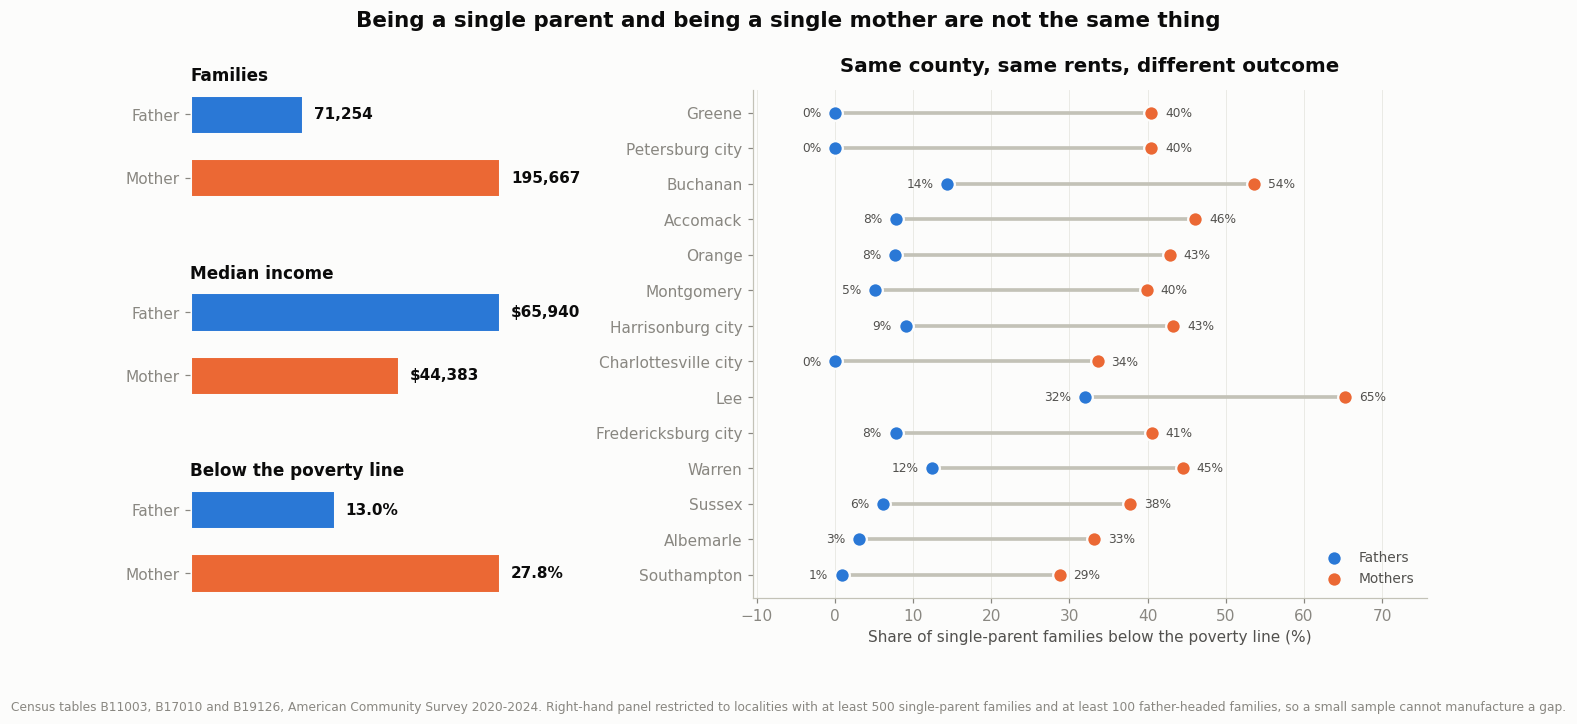

In [4]:
fig = plt.figure(figsize=(14.5, 6.0))
grid = fig.add_gridspec(3, 2, width_ratios=[0.85, 1.3], hspace=0.75, wspace=0.22)

# Three measures, three axes: they share no unit, so they must not share a scale.
MEASURES = [
    ("Families", row.father_families, row.mother_families, "{:,.0f}"),
    ("Median income", row.father_income, row.mother_income, "${:,.0f}"),
    ("Below the poverty line", father_rate, mother_rate, "{:.1f}%"),
]
for i, (title, father_value, mother_value, fmt) in enumerate(MEASURES):
    ax = fig.add_subplot(grid[i, 0])
    ax.barh([1, 0], [father_value, mother_value], height=0.62,
            color=[CAT[0], CAT[1]], edgecolor=SURFACE, linewidth=2)
    for j, value in enumerate([mother_value, father_value]):
        ax.annotate(fmt.format(value), (value, j), xytext=(7, 0), textcoords="offset points",
                    va="center", fontsize=10, fontweight="bold", color=INK)
    ax.set_yticks([1, 0], ["Father", "Mother"])
    ax.set_title(title, fontsize=11, pad=6, loc="left")
    ax.set_xticks([]); ax.margins(x=0.42)
    for spine in ("bottom", "left"):
        ax.spines[spine].set_visible(False)

ax_right = fig.add_subplot(grid[:, 1])
axes = [None, ax_right]
top = solid.nlargest(14, "gap").iloc[::-1]
y = np.arange(len(top))
ax_right.hlines(y, top["father_rate"], top["mother_rate"], color=AXIS, linewidth=2.4, zorder=1)
ax_right.scatter(top["father_rate"], y, s=92, facecolor=CAT[0], edgecolor=SURFACE,
                linewidth=1.5, zorder=3, label="Fathers")
ax_right.scatter(top["mother_rate"], y, s=92, facecolor=CAT[1], edgecolor=SURFACE,
                linewidth=1.5, zorder=3, label="Mothers")
for i, r in enumerate(top.itertuples()):
    ax_right.annotate(f"{r.father_rate:.0f}%", (r.father_rate, i), xytext=(-9, 0),
                     textcoords="offset points", ha="right", va="center", fontsize=8, color=INK_2)
    ax_right.annotate(f"{r.mother_rate:.0f}%", (r.mother_rate, i), xytext=(9, 0),
                     textcoords="offset points", ha="left", va="center", fontsize=8, color=INK_2)
ax_right.set_yticks(y, [n.replace(" County", "") for n in top["locality"]])
ax_right.set_xlabel("Share of single-parent families below the poverty line (%)")
ax_right.set_title("Same county, same rents, different outcome", pad=12)
ax_right.grid(axis="x", alpha=0.7); ax_right.set_axisbelow(True); ax_right.margins(x=0.16)
ax_right.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="lower right")

fig.suptitle("Being a single parent and being a single mother are not the same thing",
             fontsize=14, fontweight="bold", color=INK, y=1.0)
fig.text(0.5, -0.06, "Census tables B11003, B17010 and B19126, American Community Survey 2020-2024. "
         "Right-hand panel restricted to localities with at least 500 single-parent families and "
         "at least 100 father-headed families, so a small sample cannot manufacture a gap.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.savefig(FIGDIR / "s02_gender_split.png", bbox_inches="tight")
plt.show()

### Why this matters for everything that follows

The affordability calculation in the later chapters uses the income of **mothers** raising children
alone. That is a deliberate choice and it needs stating, because it is not neutral.

The Census Bureau publishes separate median incomes for mother-headed and father-headed families and
there is no valid way to combine them — you cannot average two medians. The father figure is also
missing in 29 of the 133 localities, because the samples are too small to publish.

So the later numbers describe **a mother raising children alone**. They are too pessimistic for the
27 percent of these families headed by a father, and the notebook says so wherever the figure appears
rather than quietly letting "single parent" stand in for "single mother".

## Chapter 3 — Race, and an honest wall

The obvious next question is how this varies by race. Here the data stops part of the way, and it is
better to say exactly where.

**What does not exist.** The Census Bureau does not publish income for single-parent families by race.
No table crosses family type, race and income together. So there is no published answer to "what does
a Black mother raising children alone in Virginia earn". Any figure claiming to be that would be
constructed, not measured.

**What does exist.** Two things, and they are worth having:

1. The **poverty rate for single-parent families**, by the race of the parent — Census table B17010
   and its racial iterations. This one genuinely crosses family type with race.
2. **Median family income by race**, but for *all* families rather than single-parent families —
   Census table B19113 and its iterations.

**One more limit.** By race these figures are only reliable **statewide**. Broken down to individual
counties the counts collapse toward zero in most places, so a locality map by race would be noise
dressed up as detail. The notebook does not draw one.

In [5]:
RACE_GROUPS = [("H", "White alone, not Hispanic"), ("B", "Black alone"),
               ("I", "Hispanic or Latino"), ("D", "Asian alone"),
               ("C", "American Indian and Alaska Native"), ("G", "Two or more races")]

records = []
for suffix, label in RACE_GROUPS:
    poverty = census([f"B17010{suffix}_{i:03d}E" for i in (11, 17, 31, 37)]).iloc[0]
    below = poverty[f"B17010{suffix}_011E"] + poverty[f"B17010{suffix}_017E"]
    universe = below + poverty[f"B17010{suffix}_031E"] + poverty[f"B17010{suffix}_037E"]
    income = census([f"B19113{suffix}_001E"]).iloc[0][f"B19113{suffix}_001E"]
    records.append({"group": label, "single_parent_families": universe,
                    "below_poverty": below,
                    "single_parent_poverty_rate": below / universe * 100 if universe else np.nan,
                    "median_income_all_families": income})

overall = census([f"B17010_{i:03d}E" for i in (11, 17, 31, 37)] + ["B19113_001E"]).iloc[0]
all_below = overall["B17010_011E"] + overall["B17010_017E"]
all_universe = all_below + overall["B17010_031E"] + overall["B17010_037E"]
records.append({"group": "All families", "single_parent_families": all_universe,
                "below_poverty": all_below,
                "single_parent_poverty_rate": all_below / all_universe * 100,
                "median_income_all_families": overall["B19113_001E"]})

race = pd.DataFrame(records).sort_values("single_parent_poverty_rate", ascending=False)
print("Virginia, statewide only. The poverty rate is for SINGLE-PARENT families;")
print("the income column is for ALL families of that group, because the single-parent")
print("figure by race is not published.")
display(race.round(1).reset_index(drop=True))
race.to_csv(OUTDIR / "story_race_statewide.csv", index=False)

Virginia, statewide only. The poverty rate is for SINGLE-PARENT families;
the income column is for ALL families of that group, because the single-parent
figure by race is not published.


,group,single_parent_families,below_poverty,single_parent_poverty_rate,median_income_all_families
0,Black alone,112163,31528,28.1,80724
1,Hispanic or Latino,46469,12853,27.7,94722
2,Two or more races,31527,8180,25.9,109332
3,American Indian and Alaska Native,1724,426,24.7,85271
4,All families,315527,75543,23.9,115213
5,"White alone, not Hispanic",133975,26878,20.1,124990
6,Asian alone,9029,1171,13.0,158702


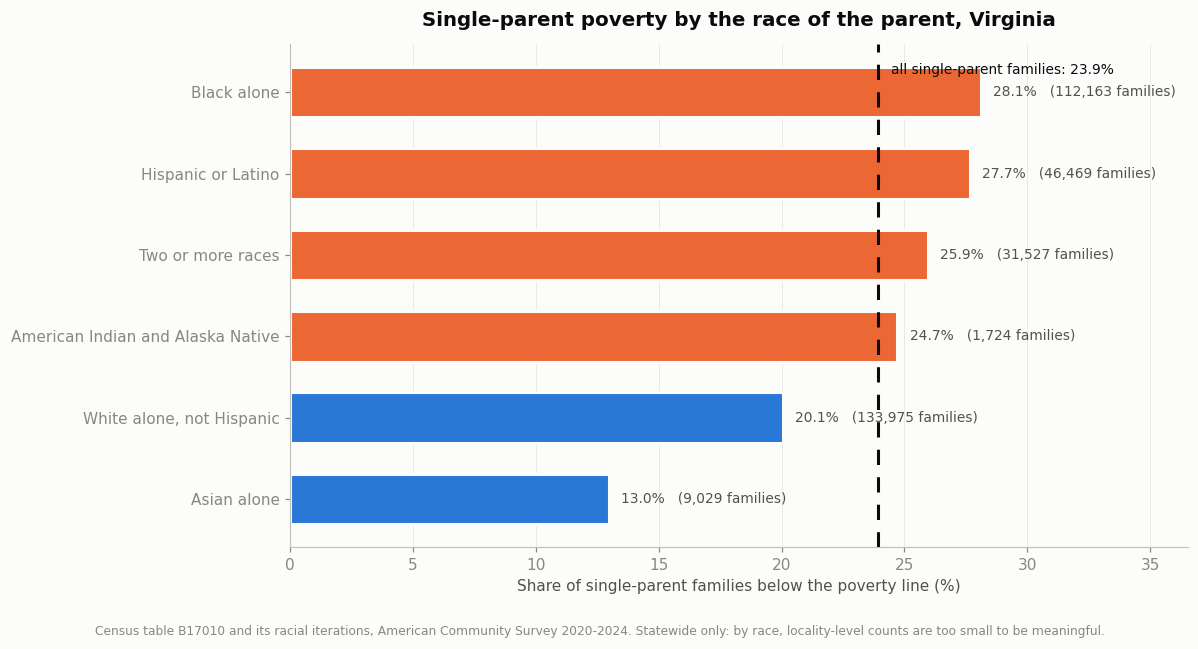

In [6]:
plot = race.loc[race["group"] != "All families"].sort_values("single_parent_poverty_rate")
fig, ax = plt.subplots(figsize=(11, 5.6))
y = np.arange(len(plot))
overall_rate = race.loc[race["group"] == "All families", "single_parent_poverty_rate"].iloc[0]
colours = [CAT[1] if v > overall_rate else CAT[0] for v in plot["single_parent_poverty_rate"]]
ax.barh(y, plot["single_parent_poverty_rate"], height=0.62, color=colours,
        edgecolor=SURFACE, linewidth=2)
ax.axvline(overall_rate, color=INK, linewidth=2, linestyle=(0, (5, 4)), zorder=4)
ax.annotate(f"all single-parent families: {overall_rate:.1f}%",
            xy=(overall_rate, 1.0), xycoords=("data", "axes fraction"),
            xytext=(8, -12), textcoords="offset points", fontsize=9, color=INK, va="top")
for i, r in enumerate(plot.itertuples()):
    ax.annotate(f"{r.single_parent_poverty_rate:.1f}%   ({r.single_parent_families:,.0f} families)",
                (r.single_parent_poverty_rate, i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.set_yticks(y, plot["group"])
ax.set_xlabel("Share of single-parent families below the poverty line (%)")
ax.set_title("Single-parent poverty by the race of the parent, Virginia", pad=12)
ax.grid(axis="x", alpha=0.7); ax.set_axisbelow(True); ax.margins(x=0.30)
fig.text(0.5, -0.04,
         "Census table B17010 and its racial iterations, American Community Survey 2020-2024. "
         "Statewide only: by race, locality-level counts are too small to be meaningful.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.tight_layout()
fig.savefig(FIGDIR / "s03_race_poverty.png", bbox_inches="tight")
plt.show()

## Chapter 4 — Where these families live, and the two different answers

"Where" has two answers and they point in opposite directions. One is about **concentration** — how
many families there are. The other is about **share** — how large a part of the community they are.
A programme designed off the first will miss the places where the second is highest.

In [7]:
# The locality table is produced by the derivation notebook, which validates every count against
# published state totals and carries the margin of error on each one. Nothing here is re-derived.
MASTER = OUTDIR / "va_single_parent_complete_budget_acs2024_5yr.csv"
assert MASTER.exists(), (
    f"{MASTER} not found. Run va_single_parent_affordability.ipynb first — it writes this file."
)
va = pd.read_csv(MASTER, dtype={"geoid": str})
assert len(va) == 133, f"expected 133 localities, found {len(va)}"
assert va["single_parent_families"].sum() == 266921, "locality counts no longer reconcile"

ranked = va.sort_values("single_parent_families", ascending=False).reset_index(drop=True)
ranked["cumulative_share"] = (
    ranked["single_parent_families"].cumsum() / ranked["single_parent_families"].sum() * 100
)
half = int((ranked["cumulative_share"] < 50).sum()) + 1

print(f"Virginia has {va['single_parent_families'].sum():,} single-parent families "
      f"across {len(va)} localities.")
print(f"  Half of them live in just {half} localities.")
print(f"  The share of all families that are single-parent runs from "
      f"{va['single_parent_share_pct'].min():.1f} percent to "
      f"{va['single_parent_share_pct'].max():.1f} percent.")
print()

cities = va[va["locality_type"] == "Independent city"]
counties = va[va["locality_type"] == "County"]
print(f"  Independent cities ({len(cities)}): average share "
      f"{cities['single_parent_share_pct'].mean():.1f} percent")
print(f"  Counties ({len(counties)}):           average share "
      f"{counties['single_parent_share_pct'].mean():.1f} percent")
correlation = va[["single_parent_share_pct", "median_income_single_mother"]].corr().iloc[0, 1]
print(f"  Where the share is higher, the mother's income is lower "
      f"(correlation {correlation:.2f}).")
print()

print("Most single-parent families, by count:")
display(ranked.loc[:7, ["locality", "single_parent_families", "single_parent_share_pct"]]
        .round(1))
print("Largest share of all families, among localities with at least 300 such families:")
display(va[va["single_parent_families"] >= 300]
        .nlargest(8, "single_parent_share_pct")
        [["locality", "locality_type", "single_parent_share_pct", "single_parent_families"]]
        .round(1).reset_index(drop=True))

Virginia has 266,921 single-parent families across 133 localities.
  Half of them live in just 11 localities.
  The share of all families that are single-parent runs from 1.7 percent to 34.1 percent.

  Independent cities (38): average share 18.2 percent
  Counties (95):           average share 10.5 percent
  Where the share is higher, the mother's income is lower (correlation -0.41).

Most single-parent families, by count:


,locality,single_parent_families,single_parent_share_pct
0,Fairfax County,23500,8.1
1,Virginia Beach city,17277,14.5
2,Prince William County,13330,11.2
3,Chesterfield County,12546,12.4
4,Henrico County,12149,14.0
5,Norfolk city,11156,21.2
6,Richmond city,9409,20.6
7,Chesapeake city,9371,14.1


Largest share of all families, among localities with at least 300 such families:


,locality,locality_type,single_parent_share_pct,single_parent_families
0,Emporia city,Independent city,34.1,453
1,Covington city,Independent city,28.6,407
2,Petersburg city,Independent city,27.3,1771
3,Danville city,Independent city,24.7,2434
4,Portsmouth city,Independent city,24.5,5921
5,Franklin city,Independent city,23.9,557
6,Buena Vista city,Independent city,23.9,409
7,Greensville County,County,23.6,513


The two lists barely overlap. Fairfax County has the most single-parent families of anywhere in
Virginia — about 23,500 — and one of the **lowest** shares, because it has a very large number of
families of every kind. Emporia city has about 450, and more than a third of all its families with
children are headed by one parent.

Notice also that eight of the ten highest shares are **independent cities**, not counties. Virginia's
independent cities are small, tightly drawn and separate from the counties around them, so a city's
figures are not diluted by its suburbs the way they would be elsewhere. That is a feature of Virginia's
unusual local government structure, and it makes the concentration visible rather than averaged away.

In [8]:
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon as MplPolygon

CMAP_SEQ = LinearSegmentedColormap.from_list("va_seq", SEQ_BLUE)

def fetch(url):
    response = requests.get(url, timeout=180,
                            headers={"User-Agent": "virginia-datathon-2026"})
    response.raise_for_status()
    return response.content

# Locality outlines, live from the United States Census Bureau TIGERweb service, generalised
# to roughly eleven metres so the whole state is a quarter of a megabyte.
TIGERWEB = (
    "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/"
    "MapServer/1/query?where=STATE%3D%2751%27&outFields=GEOID,NAME&returnGeometry=true"
    "&outSR=4326&geometryPrecision=4&maxAllowableOffset=0.002&f=geojson"
)
geojson = json.loads(fetch(TIGERWEB).decode("utf-8"))

def exterior_rings(feature):
    geometry = feature["geometry"]
    if geometry["type"] == "Polygon":
        return [geometry["coordinates"][0]]
    return [polygon[0] for polygon in geometry["coordinates"]]

SHAPES = {f["properties"]["GEOID"]: exterior_rings(f) for f in geojson["features"]}
assert set(SHAPES) == set(va["geoid"]), "map outlines do not match the analysis table"
CENTROIDS = {
    g: (np.mean([p[0] for r in rs for p in r]), np.mean([p[1] for r in rs for p in r]))
    for g, rs in SHAPES.items()
}
VA_ASPECT = 1 / np.cos(np.radians(37.5))  # a degree of longitude is shorter than a degree of latitude
print(f"Outlines loaded for {len(SHAPES)} localities; every identifier matched.")

def choropleth(ax, series, cmap, norm, label_geoids=(), label_fmt="{:.0f}", label_offsets=None):
    values = series.to_dict()
    patches, facecolors = [], []
    for geoid, ring_list in SHAPES.items():
        value = values.get(geoid)
        known = value is not None and pd.notna(value)
        for ring in ring_list:
            patches.append(MplPolygon(ring, closed=True))
            facecolors.append(cmap(norm(value)) if known else NO_DATA)
    ax.add_collection(PatchCollection(patches, facecolors=facecolors,
                                      edgecolor=SURFACE, linewidth=0.35))
    for geoid in label_geoids:
        x, y = CENTROIDS[geoid]
        dx, dy = (label_offsets or {}).get(geoid, (0, 0))
        name = va.loc[va.geoid == geoid, "locality"].iloc[0].replace(" County", "")
        ax.annotate(f"{name}\n" + label_fmt.format(values[geoid]), (x, y),
                    xytext=(dx, dy), textcoords="offset points", ha="center", va="center",
                    fontsize=7.5, color=INK, zorder=6,
                    bbox=dict(boxstyle="round,pad=0.24", fc=SURFACE, ec=AXIS, lw=0.5, alpha=0.95),
                    arrowprops=(dict(arrowstyle="-", color=INK_MUTED, lw=0.7,
                                     shrinkA=1, shrinkB=2) if (dx or dy) else None))
    ax.autoscale_view(); ax.margins(x=0.06, y=0.16)
    ax.set_aspect(VA_ASPECT); ax.axis("off")

Outlines loaded for 133 localities; every identifier matched.


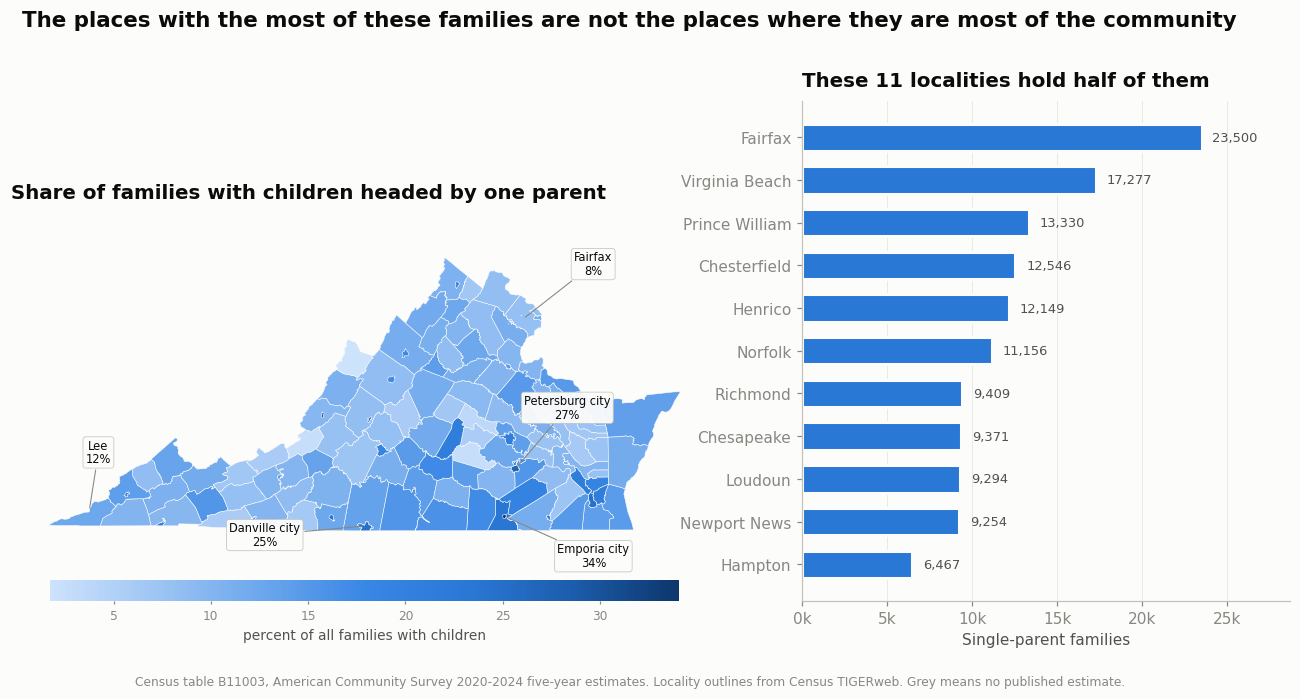

In [9]:
fig = plt.figure(figsize=(15, 5.9))
grid = fig.add_gridspec(1, 2, width_ratios=[1.45, 1], wspace=0.14)

share = va.set_index("geoid")["single_parent_share_pct"]
ax_map = fig.add_subplot(grid[0, 0])
norm = Normalize(vmin=float(share.min()), vmax=float(share.max()))
HIGHLIGHT = {
    "51595": (58, -26),   # Emporia city
    "51730": (34, 40),    # Petersburg city
    "51590": (-66, -6),   # Danville city
    "51059": (46, 36),    # Fairfax County
    "51105": (6, 38),     # Lee County
}
choropleth(ax_map, share, CMAP_SEQ, norm, label_geoids=list(HIGHLIGHT),
           label_fmt="{:.0f}%", label_offsets=HIGHLIGHT)
ax_map.set_anchor("N")
ax_map.set_title("Share of families with children headed by one parent", pad=10, loc="left")
bar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=CMAP_SEQ), ax=ax_map,
                   orientation="horizontal", fraction=0.042, pad=0.01, aspect=30)
bar.set_label("percent of all families with children", color=INK_2, fontsize=9)
bar.outline.set_visible(False)
bar.ax.tick_params(labelsize=8, colors=INK_MUTED, length=2)

ax_bars = fig.add_subplot(grid[0, 1])
top = ranked.loc[:half - 1].iloc[::-1]
y = np.arange(len(top))
ax_bars.barh(y, top["single_parent_families"], height=0.64, color=CAT[0],
             edgecolor=SURFACE, linewidth=2)
for i, r in enumerate(top.itertuples()):
    ax_bars.annotate(f"{r.single_parent_families:,.0f}", (r.single_parent_families, i),
                     xytext=(7, 0), textcoords="offset points", va="center",
                     fontsize=8.5, color=INK_2)
ax_bars.set_yticks(y, [n.replace(" County", "").replace(" city", "") for n in top["locality"]])
ax_bars.set_xlabel("Single-parent families")
ax_bars.set_title(f"These {half} localities hold half of them", pad=10, loc="left")
ax_bars.xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k")
ax_bars.grid(axis="x", alpha=0.7); ax_bars.set_axisbelow(True); ax_bars.margins(x=0.22)

fig.suptitle("The places with the most of these families are not the places where they are "
             "most of the community", fontsize=14, fontweight="bold", color=INK, y=1.02)
fig.text(0.5, -0.02, "Census table B11003, American Community Survey 2020-2024 five-year "
         "estimates. Locality outlines from Census TIGERweb. Grey means no published estimate.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.savefig(FIGDIR / "s04_where_they_live.png", bbox_inches="tight")
plt.show()

## Chapter 5 — What it costs to live there

Now the other side of the ledger. For every locality the derivation notebook assembles the cost of
five things a parent with one young child cannot avoid:

| Item | Source | Varies by locality |
|---|---|---|
| Rent on a two-bedroom home | Census Bureau, table B25031 | Yes |
| Childcare for a toddler | United States Department of Labor, National Database of Childcare Prices | Yes |
| Transportation | Center for Neighborhood Technology, Housing and Transportation Affordability Index | Yes |
| Food | United States Department of Agriculture, Low-Cost Food Plan | No — statewide figure |
| Health care | Medical Expenditure Panel Survey, employee share | No — statewide figure |

Nothing else is in it. No savings, no debt payment, no internet, no clothing, no childcare for a
second child, no emergency. It is deliberately the floor rather than a comfortable life, so that
anything it shows as unaffordable is unarguable.

In [10]:
COMPONENTS = [
    ("Rent, two bedrooms", "rent_annual_2br", CAT[0]),
    ("Childcare, one toddler", "childcare_toddler_annual", CAT[1]),
    ("Transportation", "transport_cost_annual", CAT[2]),
    ("Food", "food_annual", CAT[3]),
    ("Health care", "health_care_annual", CAT[4]),
]
budget = va.dropna(subset=["budget_preschool_annual", "median_income_single_mother"]).copy()
print(f"{len(budget)} of {len(va)} localities have both a published budget and a published "
      f"median income for mothers raising children alone.")
print(f"  Median annual budget:            ${budget['budget_preschool_annual'].median():>9,.0f}")
print(f"  Median income, mother alone:     ${budget['median_income_single_mother'].median():>9,.0f}")
print(f"  Median budget as share of income: {budget['budget_preschool_pct_of_income'].median():>8.0f} percent")
short = int((budget["budget_preschool_pct_of_income"] > 100).sum())
print(f"\n  In {short} of {len(budget)} localities the floor budget costs more than the whole "
      f"median income — before a single dollar of tax and before any help arrives.")

print("\nWhat the money goes on, as a share of the budget (median across localities):")
for label, column, _ in COMPONENTS:
    pct = (va[column] / va["budget_preschool_annual"]).median() * 100
    print(f"  {label:<24} {pct:>5.1f} percent    "
          f"${va[column].median():>8,.0f}  (${va[column].min():,.0f} to ${va[column].max():,.0f})")

120 of 133 localities have both a published budget and a published median income for mothers raising children alone.
  Median annual budget:            $   52,274
  Median income, mother alone:     $   40,970
  Median budget as share of income:      129 percent

  In 103 of 120 localities the floor budget costs more than the whole median income — before a single dollar of tax and before any help arrives.

What the money goes on, as a share of the budget (median across localities):
  Rent, two bedrooms        23.5 percent    $  12,192  ($7,548 to $31,992)
  Childcare, one toddler    16.3 percent    $   8,481  ($5,190 to $28,621)
  Transportation            31.7 percent    $  15,860  ($11,119 to $19,896)
  Food                      19.0 percent    $   9,864  ($9,864 to $9,864)
  Health care               11.1 percent    $   5,736  ($5,736 to $5,736)


The largest single line is not rent and it is not childcare. It is **transportation** — about a third
of the budget, and the only item that is high everywhere, because the figure is the real cost of
owning and running the cars a household in that locality actually needs. In most of Virginia there is
no alternative to a car, and the cost of one does not fall when incomes do.

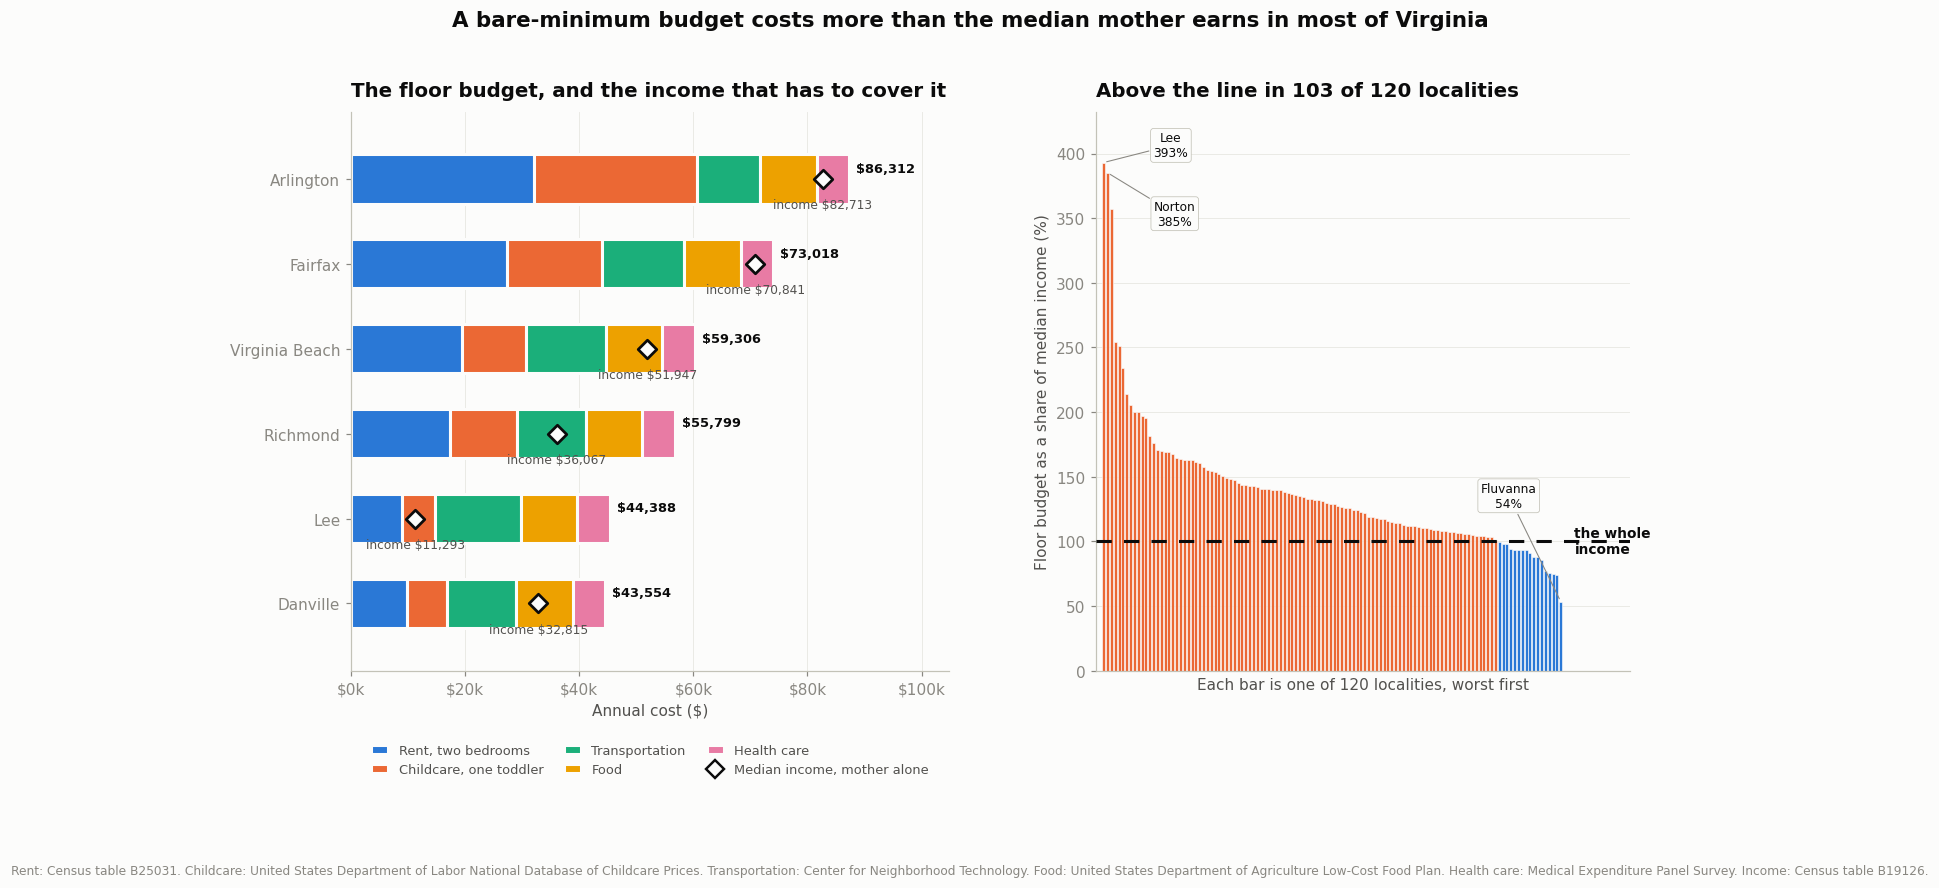

In [11]:
fig = plt.figure(figsize=(15, 6.6))
grid = fig.add_gridspec(1, 2, width_ratios=[1.12, 1], wspace=0.26)

# Left: what the budget is made of, in dollars, across the range of Virginia localities.
picks = ["Lee County", "Danville city", "Richmond city", "Virginia Beach city",
         "Fairfax County", "Arlington County"]
panel = budget[budget["locality"].isin(picks)].sort_values("budget_preschool_annual")
ax = fig.add_subplot(grid[0, 0])
y = np.arange(len(panel))
left = np.zeros(len(panel))
for label, column, colour in COMPONENTS:
    width = panel[column].to_numpy(dtype=float)
    ax.barh(y, width, left=left, height=0.58, color=colour,
            edgecolor=SURFACE, linewidth=2, label=label)
    left = left + width
ax.scatter(panel["median_income_single_mother"], y, marker="D", s=74, zorder=5,
           facecolor=SURFACE, edgecolor=INK, linewidth=1.8)
for i, r in enumerate(panel.itertuples()):
    ax.annotate(f"${r.budget_preschool_annual:,.0f}", (r.budget_preschool_annual, i),
                xytext=(8, 7), textcoords="offset points", va="center",
                fontsize=8.5, fontweight="bold", color=INK)
    ax.annotate(f"income ${r.median_income_single_mother:,.0f}",
                (r.median_income_single_mother, i), xytext=(0, -17),
                textcoords="offset points", ha="center", va="center",
                fontsize=8, color=INK_2)
ax.set_yticks(y, [n.replace(" County", "").replace(" city", "") for n in panel["locality"]])
ax.set_xlabel("Annual cost ($)")
ax.set_title("The floor budget, and the income that has to cover it", pad=10, loc="left")
ax.xaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
ax.grid(axis="x", alpha=0.7); ax.set_axisbelow(True); ax.margins(x=0.20, y=0.09)
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], marker="D", color="none", markerfacecolor=SURFACE,
                      markeredgecolor=INK, markeredgewidth=1.6, markersize=8))
labels.append("Median income, mother alone")
ax.legend(handles, labels, frameon=False, fontsize=8.5, labelcolor=INK_2,
          loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3,
          handlelength=1.3, columnspacing=1.6)

# Right: the same thing as a burden, for every locality that has both figures.
ax2 = fig.add_subplot(grid[0, 1])
curve = budget.sort_values("budget_preschool_pct_of_income", ascending=False).reset_index(drop=True)
x = np.arange(len(curve))
colours = [CAT[1] if v > 100 else CAT[0] for v in curve["budget_preschool_pct_of_income"]]
ax2.bar(x, curve["budget_preschool_pct_of_income"], width=0.78, color=colours,
        edgecolor=SURFACE, linewidth=0.4)
ax2.axhline(100, color=INK, linewidth=2, linestyle=(0, (5, 4)), zorder=5)
ax2.set_xlim(-2, len(curve) + 17)
ax2.annotate("the whole\nincome", xy=(len(curve) + 1, 100), xytext=(4, 0),
             textcoords="offset points", ha="left", va="center", fontsize=9,
             color=INK, fontweight="bold")
for name, offset in [("Lee County", (44, 4)), ("Norton city", (44, -34)),
                     ("Fluvanna County", (-34, 62))]:
    r = curve[curve["locality"] == name].iloc[0]
    i = int(curve.index[curve["locality"] == name][0])
    ax2.annotate(f"{name.replace(' County', '').replace(' city', '')}\n"
                 f"{r.budget_preschool_pct_of_income:.0f}%",
                 (i, r.budget_preschool_pct_of_income), xytext=offset,
                 textcoords="offset points", ha="center", fontsize=8, color=INK,
                 bbox=dict(boxstyle="round,pad=0.24", fc=SURFACE, ec=AXIS, lw=0.5),
                 arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=0.7, shrinkA=1, shrinkB=2))
ax2.set_xticks([])
ax2.set_xlabel(f"Each bar is one of {len(curve)} localities, worst first")
ax2.set_ylabel("Floor budget as a share of median income (%)")
ax2.set_title(f"Above the line in {short} of {len(curve)} localities", pad=10, loc="left")
ax2.grid(axis="y", alpha=0.7); ax2.set_axisbelow(True); ax2.margins(y=0.10)

fig.suptitle("A bare-minimum budget costs more than the median mother earns in most of Virginia",
             fontsize=14, fontweight="bold", color=INK, y=1.02)
fig.text(0.5, -0.17, "Rent: Census table B25031. Childcare: United States Department of Labor "
         "National Database of Childcare Prices. Transportation: Center for Neighborhood "
         "Technology. Food: United States Department of Agriculture Low-Cost Food Plan. Health "
         "care: Medical Expenditure Panel Survey. Income: Census table B19126.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.savefig(FIGDIR / "s05_what_it_costs.png", bbox_inches="tight")
plt.show()

### The part that surprises people

Read the right-hand panel from the right-hand end. The localities where the budget is **easiest** are
Fluvanna, Clarke, Falls Church, Manassas Park — a mix of wealthy suburbs and commuter counties. The
localities where it is hardest are Lee, Norton, Scott, Covington, Lexington — rural and small-town
places where everything is cheaper.

Cheaper, but not cheap enough. Lee County has the **lowest** floor budget of almost anywhere in
Virginia at about $44,000, and the median mother there earns about $11,300. The budget is nearly four
times her income. Falls Church has a budget of about $75,000, which is far more money, but the median
mother there earns about $100,600, so it is three quarters of her income.

**Low cost of living is not the same as affordable.** Affordability is a ratio, and in the parts of
Virginia where costs are lowest, incomes are lower still.

In [12]:
# Transportation is the clearest case of that inversion: it costs least where people can earn most.
pair = va.dropna(subset=["median_income_single_mother"]).copy()
pair["transport_pct_of_income"] = (
    pair["transport_cost_annual"] / pair["median_income_single_mother"] * 100)
quartiles = pd.qcut(pair["median_income_single_mother"], 4,
                    labels=["Lowest income quarter", "Second", "Third", "Highest income quarter"])
table = pair.groupby(quartiles, observed=True).agg(
    localities=("locality", "size"),
    median_income=("median_income_single_mother", "median"),
    transport_cost=("transport_cost_annual", "median"),
    transport_share_of_income=("transport_pct_of_income", "median"),
    cars_per_household=("autos_per_household", "median"),
    commuters_using_transit=("pct_transit_commuters", "median"),
)
print("Localities grouped into four by the income of mothers raising children alone:")
display(table.round(1))
over = int((pair["transport_pct_of_income"] > 25).sum())
print(f"Transportation alone takes more than a quarter of the median mother's income in "
      f"{over} of {len(pair)} localities.")
print("The cost barely falls as income falls, so the share rises sharply.")

Localities grouped into four by the income of mothers raising children alone:


,localities,median_income,transport_cost,transport_share_of_income,cars_per_household,commuters_using_transit
median_income_single_mother,,,,,,
Lowest income quarter,31,29050.0,15449.0,57.0,1.9,0.0
Second,30,37268.0,14965.0,40.6,1.9,1.0
Third,30,44703.0,16580.0,36.5,2.0,0.0
Highest income quarter,31,60492.0,17009.0,28.3,2.1,0.0


Transportation alone takes more than a quarter of the median mother's income in 110 of 122 localities.
The cost barely falls as income falls, so the share rises sharply.


## Chapter 6 — What help arrives, and the wall in the middle

Everything so far compares what a parent **earns** with what the locality **costs**. That is not the
whole picture, and leaving it there would overstate the problem. Virginia and the federal government
both put money into these households: refundable tax credits, food assistance, cash assistance.

So the honest question is not "can she afford it on her earnings" but **"can she afford it on what
she is actually left with"** — earnings, plus everything that arrives, minus everything that is taken.

To answer that, every locality is run through **PolicyEngine**, an open-source microsimulation model
of the American tax and benefit system. The household modelled is one parent aged thirty-two, one
child aged three, earning that locality's published median income for a mother raising children
alone, paying that locality's published childcare price.

The result is not what we expected.

In [13]:
PE = OUTDIR / "policyengine" / "by_locality_2024.json"
assert PE.exists(), f"{PE} not found — rerun policyengine/run_by_locality.py"
pe = pd.DataFrame(json.loads(PE.read_text()))
assert "error" not in pe.columns, "the PolicyEngine run contains failures"
print(f"{len(pe)} localities modelled; the other {len(va) - len(pe)} have no published median "
      f"income for mothers, no published childcare price, or neither.")

ledger = pe.merge(va[["geoid", "locality", "budget_preschool_annual"]], on="geoid",
                  suffixes=("", "_locality"))
ledger["refundable_credits"] = ledger[["eitc", "va_eitc", "ctc", "cdcc"]].sum(axis=1)
# PolicyEngine's household benefits total is food assistance, the Special Supplemental Nutrition
# Program for Women, Infants, and Children, Virginia cash assistance and school meals combined.
assert (ledger["benefits"] >= ledger[["snap", "va_tanf", "school_meals"]].sum(axis=1) - 1).all()
ledger["means_tested_benefits"] = ledger["benefits"]
ledger["change_from_earnings"] = ledger["net_income"] - ledger["income"]
ledger["gap_before_help"] = ledger["income"] - ledger["budget_preschool_annual"]
ledger["gap_after_help"] = ledger["net_income"] - ledger["budget_preschool_annual"]

print("\nAt the median, across the modelled localities:")
for label, column in [
    ("Earnings", "income"),
    ("Refundable tax credits (earned income, child, childcare, Virginia)", "refundable_credits"),
    ("Food and nutrition assistance actually received", "means_tested_benefits"),
    ("Total tax bill, after every credit is applied", "tax"),
    ("What she is left with", "net_income"),
]:
    print(f"  {label:<64} ${ledger[column].median():>9,.0f}")
print(f"\n  So at the median she ends the year with "
      f"${ledger['change_from_earnings'].median():,.0f} relative to what she earned.")
print(f"  That is true in {int((ledger['change_from_earnings'] < 0).sum())} of {len(ledger)} "
      f"localities.")

before = int((ledger["gap_before_help"] < 0).sum())
after = int((ledger["gap_after_help"] < 0).sum())
print(f"\n  Localities where the floor budget costs more than she has:")
print(f"    counting earnings only ............ {before} of {len(ledger)}")
print(f"    counting help and taxes as well ... {after} of {len(ledger)}")

flipped = ledger[(ledger["gap_before_help"] >= 0) & (ledger["gap_after_help"] < 0)]
rescued = ledger[(ledger["gap_before_help"] < 0) & (ledger["gap_after_help"] >= 0)]
print(f"\n  {len(rescued)} localities are lifted above the line by help.")
print(f"  {len(flipped)} are pushed below it:")
display(flipped[["locality", "income", "net_income", "budget_preschool_annual",
                 "gap_before_help", "gap_after_help"]]
        .sort_values("gap_after_help").round(0).reset_index(drop=True))

122 localities modelled; the other 11 have no published median income for mothers, no published childcare price, or neither.

At the median, across the modelled localities:
  Earnings                                                         $   40,410
  Refundable tax credits (earned income, child, childcare, Virginia) $    4,323
  Food and nutrition assistance actually received                  $      254
  Total tax bill, after every credit is applied                    $    1,756
  What she is left with                                            $   39,156

  So at the median she ends the year with $-1,502 relative to what she earned.
  That is true in 66 of 122 localities.

  Localities where the floor budget costs more than she has:
    counting earnings only ............ 103 of 122
    counting help and taxes as well ... 114 of 122

  0 localities are lifted above the line by help.
  11 are pushed below it:


,locality,income,net_income,budget_preschool_annual,gap_before_help,gap_after_help
0,Goochland County,68550.0,57923.0,67450.0,1100.0,-9527.0
1,James City County,58765.0,50623.0,58294.0,471.0,-7671.0
2,Fauquier County,60492.0,51912.0,59057.0,1435.0,-7145.0
3,Loudoun County,83626.0,69170.0,76267.0,7359.0,-7097.0
4,York County,64432.0,54851.0,60296.0,4136.0,-5445.0
5,King George County,62734.0,53584.0,58654.0,4080.0,-5070.0
6,Nelson County,57745.0,49862.0,54529.0,3216.0,-4667.0
7,Powhatan County,56219.0,48724.0,52483.0,3736.0,-3759.0
8,Botetourt County,56607.0,49014.0,52756.0,3851.0,-3742.0
9,Stafford County,74654.0,62477.0,65943.0,8711.0,-3466.0


### Read that carefully, because it is the opposite of the expected result

Netting the help in made the problem **worse**, not better. The number of localities where a
bare-minimum budget costs more than the family has rises from 103 to 114.

The reason is arithmetic, not politics. At a median income of about $40,400 a mother is **above** the
limit for almost every means-tested programme — the median amount of food and
nutrition assistance actually received across these localities is $254 a year — while being firmly **inside** the tax system,
where payroll tax is owed from the first dollar. The refundable credits are real and substantial, but
they do not cover the bill.

Eleven localities cross from "just about managing" to "short", and every one of them is a suburban or
exurban county — Loudoun, Stafford, Fauquier, James City, York, Goochland, New Kent, Powhatan,
Botetourt, King George, Nelson. **Nowhere is lifted above the line.** These are not the poorest
places in Virginia. They are the places where a parent earns too much to qualify for help and not
enough to cover the cost.

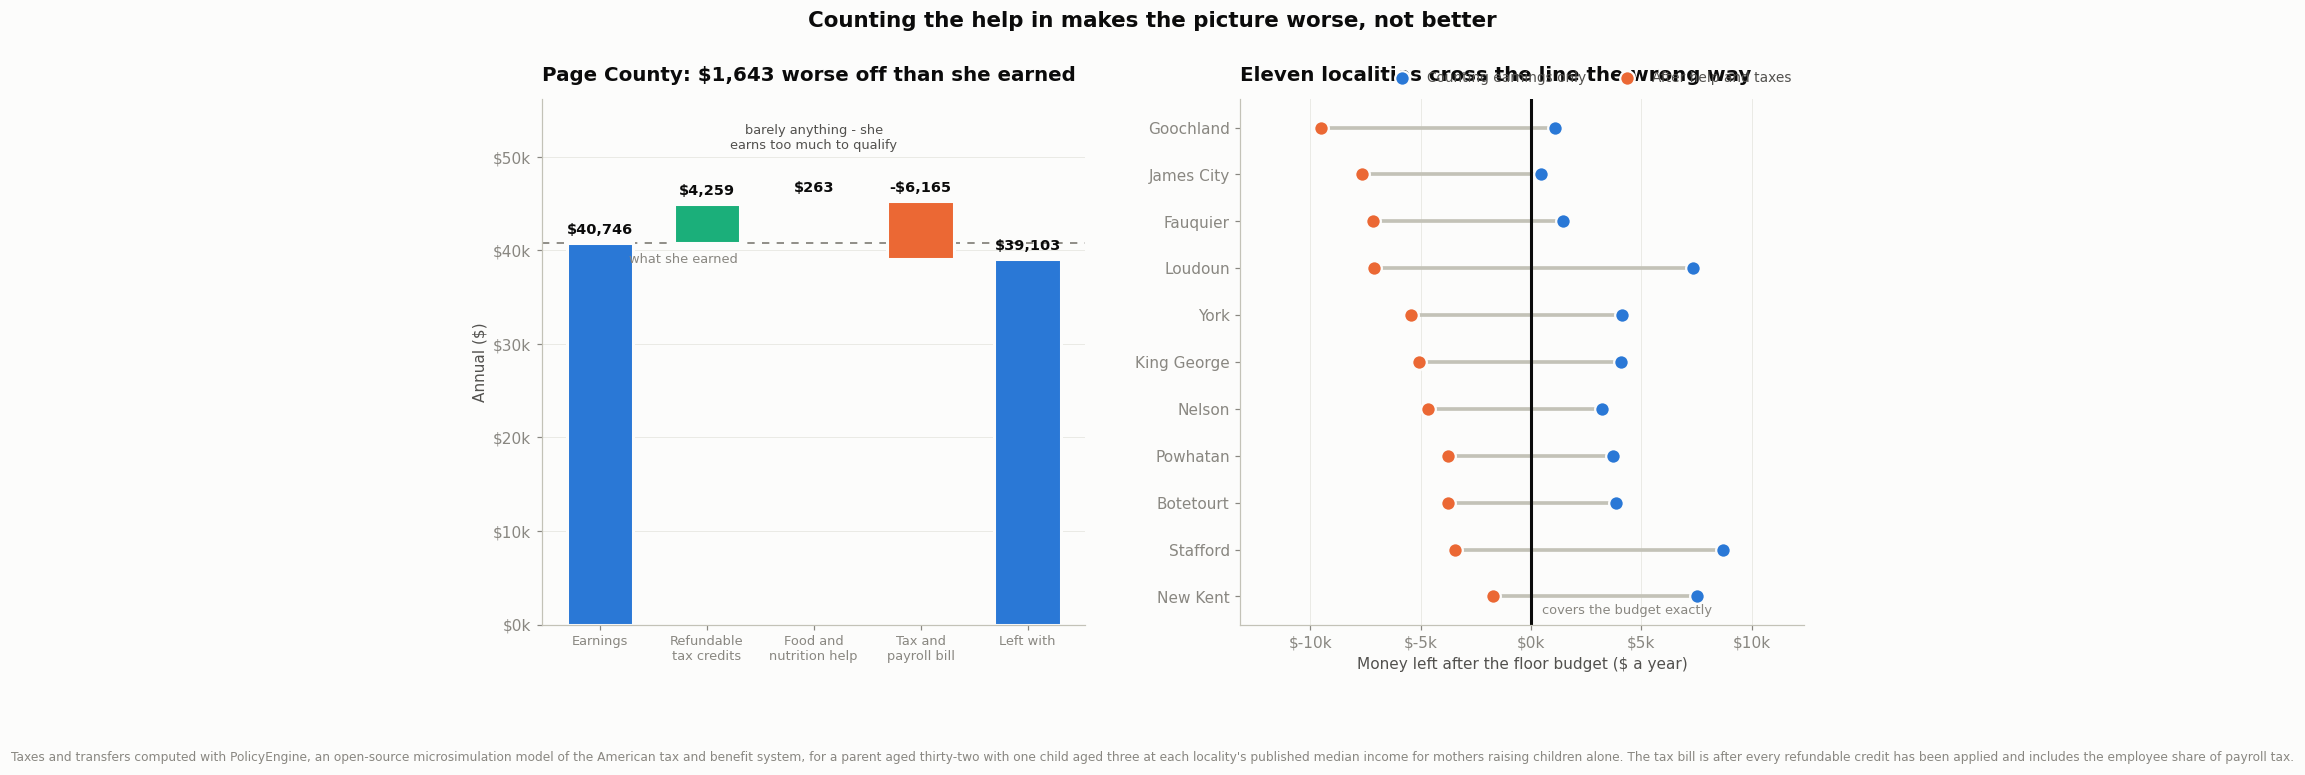

In [14]:
fig = plt.figure(figsize=(14.8, 6.2))
grid = fig.add_gridspec(1, 2, width_ratios=[1.08, 1.12], wspace=0.28)

# Left: one household's ledger as a waterfall. The median of separate columns does not add up to
# the median of their total, so this is drawn for the single locality whose earnings sit closest to
# the statewide median. Every bar then ties exactly, with no arithmetic sleight of hand.
typical = ledger.iloc[(ledger["income"] - ledger["income"].median()).abs().argsort()].iloc[0]
earnings = float(typical["income"])
credits = float(typical["refundable_credits"])
benefits_received = float(typical["means_tested_benefits"])
gross_tax = float(typical["tax"]) + credits   # the bill before refundable credits are applied
left_with = float(typical["net_income"])
assert abs(earnings + credits + benefits_received - gross_tax - left_with) < 1.0, \
    "the waterfall does not balance"

steps = [("Earnings", earnings, CAT[0], 0.0),
         ("Refundable\ntax credits", credits, CAT[2], earnings),
         ("Food and\nnutrition help", benefits_received, CAT[2], earnings + credits),
         ("Tax and\npayroll bill", -gross_tax, CAT[1], earnings + credits + benefits_received),
         ("Left with", left_with, CAT[0], 0.0)]
ax = fig.add_subplot(grid[0, 0])
x = np.arange(len(steps))
for i, (label, value, colour, base) in enumerate(steps):
    bottom = base if value >= 0 else base + value
    height = max(abs(value), earnings * 0.004)   # a near-zero step still has to be visible
    ax.bar(i, height, bottom=bottom, width=0.62, color=colour, edgecolor=SURFACE, linewidth=2)
    if 0 < i < len(steps) - 1:
        ax.plot([i - 0.31, i + 0.31], [base, base], color=AXIS, linewidth=1, zorder=0)
    ax.annotate(f"{'-' if value < 0 else ''}${abs(value):,.0f}", (i, bottom + height),
                xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9.5,
                fontweight="bold", color=INK)
ax.annotate("barely anything - she\nearns too much to qualify",
            (2, earnings + credits), xytext=(0, 36), textcoords="offset points",
            ha="center", fontsize=8.5, color=INK_2)
ax.axhline(earnings, color=INK_MUTED, linewidth=1.2, linestyle=(0, (4, 4)), zorder=0)
ax.annotate("what she earned", xy=(0.26, earnings), xycoords=("axes fraction", "data"),
            xytext=(0, -6), textcoords="offset points", ha="center", va="top",
            fontsize=8.5, color=INK_MUTED)
ax.set_xticks(x, [row[0] for row in steps], fontsize=8.5)
ax.set_ylabel("Annual ($)")
ax.yaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
ax.set_title(f"{typical['locality']}: ${earnings - left_with:,.0f} worse off than she earned",
             pad=12, loc="left")
ax.grid(axis="y", alpha=0.7); ax.set_axisbelow(True); ax.margins(y=0.24)

# Right: the eleven localities help pushes below the line.
ax2 = fig.add_subplot(grid[0, 1])
show = flipped.sort_values("gap_after_help").iloc[::-1]
y = np.arange(len(show))
ax2.hlines(y, show["gap_before_help"], show["gap_after_help"], color=AXIS, linewidth=2.4, zorder=1)
ax2.scatter(show["gap_before_help"], y, s=92, facecolor=CAT[0], edgecolor=SURFACE,
            linewidth=1.5, zorder=3, label="Counting earnings only")
ax2.scatter(show["gap_after_help"], y, s=92, facecolor=CAT[1], edgecolor=SURFACE,
            linewidth=1.5, zorder=3, label="After help and taxes")
ax2.axvline(0, color=INK, linewidth=2, zorder=2)
ax2.annotate("covers the budget exactly", xy=(0, 0.015), xycoords=("data", "axes fraction"),
             xytext=(7, 0), textcoords="offset points", fontsize=8.5, color=INK_MUTED,
             va="bottom")
ax2.set_yticks(y, [n.replace(" County", "") for n in show["locality"]])
ax2.set_xlabel("Money left after the floor budget ($ a year)")
ax2.xaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
ax2.set_title("Eleven localities cross the line the wrong way", pad=12, loc="left")
ax2.grid(axis="x", alpha=0.7); ax2.set_axisbelow(True); ax2.margins(x=0.20, y=0.06)
ax2.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="lower right",
           bbox_to_anchor=(1.0, 1.005), ncol=2)

fig.suptitle("Counting the help in makes the picture worse, not better",
             fontsize=14, fontweight="bold", color=INK, y=1.01)
fig.text(0.5, -0.09, "Taxes and transfers computed with PolicyEngine, an open-source "
         "microsimulation model of the American tax and benefit system, for a parent aged "
         "thirty-two with one child aged three at each locality's published median income for "
         "mothers raising children alone. The tax bill is after every refundable credit has "
         "been applied and includes the employee share of payroll tax.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.savefig(FIGDIR / "s06_help_and_taxes.png", bbox_inches="tight")
plt.show()

### The wall itself

The chapter is called "the wall in the middle" because of what happens to a parent who gets a raise.

Virginia sets the gross income limit for food assistance at **200 percent of the federal poverty
guideline** — this is written into the Code of Virginia at section 63.2-801, which also abolishes the
asset test. For a parent and one child in 2024 that limit is about **$40,880 a year**. Below it, food
assistance is available. One dollar above it, all of it stops at once.

To see what that does, the same household is run through PolicyEngine again at every earnings level
from nothing to $80,000, in three places: Arlington County, where rent is highest in the state;
Richmond city; and Lee County, in the far southwest, where everything is cheapest.

In [15]:
SWEEP = OUTDIR / "policyengine" / "earnings_sweep_2024.json"
assert SWEEP.exists(), f"{SWEEP} not found — rerun policyengine/run_earnings_sweep.py"
sweep = pd.DataFrame(json.loads(SWEEP.read_text())).sort_values(["locality", "earnings"])
assert "error" not in sweep.columns, "the earnings sweep contains failures"

sweep["kept_per_extra_dollar"] = sweep.groupby("locality")["net_income"].diff() / \
                                 sweep.groupby("locality")["earnings"].diff()
print(f"{sweep['locality'].nunique()} localities, "
      f"{sweep['earnings'].nunique()} earnings levels each.")

print("\nWhat a $4,000 raise from $38,000 is worth, after taxes and lost assistance:")
for name in ["Arlington County", "Richmond city", "Lee County"]:
    g = sweep[sweep["locality"] == name].set_index("earnings")
    change = g.loc[42000, "net_income"] - g.loc[38000, "net_income"]
    print(f"  {name:<18} ${g.loc[38000, 'net_income']:>9,.0f}  ->  "
          f"${g.loc[42000, 'net_income']:>9,.0f}   "
          f"{'a loss of' if change < 0 else 'a gain of'} ${abs(change):,.0f}")

print("\nWhere food assistance stops, by locality:")
for name, g in sweep.groupby("locality"):
    last = g.loc[g["snap"] > 0, "earnings"].max()
    print(f"  {name:<18} last earnings level with any food assistance: ${last:,.0f}")
print("  200 percent of the 2024 federal poverty guideline for two people: $40,880")

3 localities, 41 earnings levels each.

What a $4,000 raise from $38,000 is worth, after taxes and lost assistance:
  Arlington County   $   44,464  ->  $   39,505   a loss of $4,959
  Richmond city      $   39,559  ->  $   39,505   a loss of $54
  Lee County         $   38,317  ->  $   39,505   a gain of $1,188

Where food assistance stops, by locality:
  Arlington County   last earnings level with any food assistance: $40,000
  Lee County         last earnings level with any food assistance: $40,000
  Richmond city      last earnings level with any food assistance: $40,000
  200 percent of the 2024 federal poverty guideline for two people: $40,880


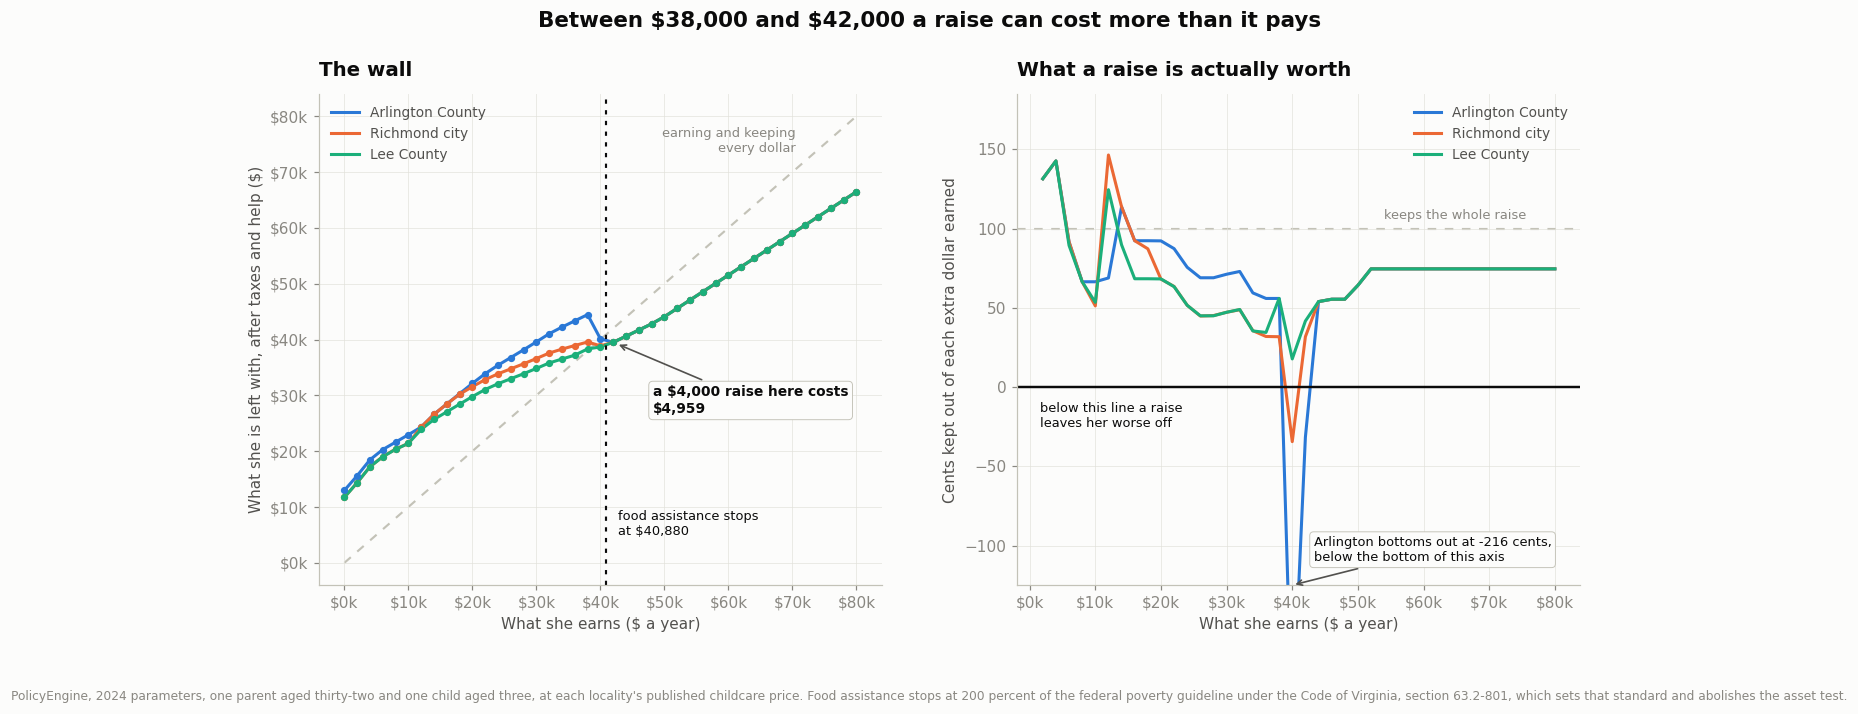

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14.8, 5.8), gridspec_kw={"wspace": 0.24})
ORDER = [("Arlington County", CAT[0]), ("Richmond city", CAT[1]), ("Lee County", CAT[2])]
LIMIT = 40880  # 200 percent of the 2024 federal poverty guideline, parent plus one child

for name, colour in ORDER:
    g = sweep[sweep["locality"] == name]
    axes[0].plot(g["earnings"], g["net_income"], color=colour, linewidth=2, label=name)
    axes[0].scatter(g["earnings"], g["net_income"], s=14, color=colour, zorder=3)
axes[0].plot([0, 80000], [0, 80000], color=AXIS, linewidth=1.4, linestyle=(0, (4, 4)), zorder=0)
axes[0].annotate("earning and keeping\nevery dollar", xy=(72000, 72000), xytext=(-6, 6),
                 textcoords="offset points", ha="right", fontsize=8.5, color=INK_MUTED)
axes[0].axvline(LIMIT, color=INK, linewidth=1.4, linestyle=(0, (2, 3)), zorder=2)
axes[0].annotate("food assistance stops\nat $40,880", xy=(LIMIT, 7000), xytext=(8, 0),
                 textcoords="offset points", fontsize=8.5, color=INK, va="center")
arl = sweep[sweep["locality"] == "Arlington County"].set_index("earnings")
axes[0].annotate(f"a $4,000 raise here costs\n"
                 f"${arl.loc[38000, 'net_income'] - arl.loc[42000, 'net_income']:,.0f}",
                 xy=(42000, arl.loc[42000, "net_income"]), xytext=(26, -46),
                 textcoords="offset points", fontsize=9, color=INK, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.3", fc=SURFACE, ec=AXIS, lw=0.6),
                 arrowprops=dict(arrowstyle="->", color=INK_2, lw=1.1, shrinkA=2, shrinkB=4))
axes[0].set_xlabel("What she earns ($ a year)")
axes[0].set_ylabel("What she is left with, after taxes and help ($)")
axes[0].set_title("The wall", pad=12, loc="left")
for axis in (axes[0].xaxis, axes[0].yaxis):
    axis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
axes[0].grid(alpha=0.7); axes[0].set_axisbelow(True)
axes[0].legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper left")

for name, colour in ORDER:
    g = sweep[sweep["locality"] == name].dropna(subset=["kept_per_extra_dollar"])
    axes[1].plot(g["earnings"], g["kept_per_extra_dollar"] * 100, color=colour, linewidth=2,
                 label=name)
axes[1].axhline(0, color=INK, linewidth=1.6, zorder=2)
axes[1].axhline(100, color=AXIS, linewidth=1.4, linestyle=(0, (4, 4)), zorder=0)
axes[1].annotate("keeps the whole raise", xy=(54000, 100), xytext=(0, 6),
                 textcoords="offset points", ha="left", fontsize=8.5, color=INK_MUTED)
axes[1].annotate("below this line a raise\nleaves her worse off", xy=(1500, 0), xytext=(0, -10),
                 textcoords="offset points", ha="left", va="top", fontsize=8.5, color=INK)

# The Arlington trough runs off the bottom of a readable scale, so the axis is cut and the true
# value is written on instead of letting one point flatten everything else.
FLOOR = -125
deepest = sweep.loc[sweep["kept_per_extra_dollar"].idxmin()]
axes[1].set_ylim(FLOOR, 185)
axes[1].annotate(f"{deepest['locality'].replace(' County', '')} bottoms out at "
                 f"{deepest['kept_per_extra_dollar'] * 100:.0f} cents,\nbelow the bottom of this axis",
                 xy=(float(deepest["earnings"]), FLOOR), xytext=(14, 16),
                 textcoords="offset points", ha="left", fontsize=8.5, color=INK,
                 bbox=dict(boxstyle="round,pad=0.3", fc=SURFACE, ec=AXIS, lw=0.6),
                 arrowprops=dict(arrowstyle="->", color=INK_2, lw=1.1, shrinkA=2, shrinkB=2))
axes[1].set_xlabel("What she earns ($ a year)")
axes[1].set_ylabel("Cents kept out of each extra dollar earned")
axes[1].set_title("What a raise is actually worth", pad=12, loc="left")
axes[1].xaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
axes[1].grid(alpha=0.7); axes[1].set_axisbelow(True)
axes[1].legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper right")

fig.suptitle(r"Between \$38,000 and \$42,000 a raise can cost more than it pays",
             fontsize=14, fontweight="bold", color=INK, y=1.01)
fig.text(0.5, -0.07, "PolicyEngine, 2024 parameters, one parent aged thirty-two and one child "
         "aged three, at each locality's published childcare price. Food assistance stops at "
         "200 percent of the federal poverty guideline under the Code of Virginia, section "
         "63.2-801, which sets that standard and abolishes the asset test.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.savefig(FIGDIR / "s07_the_wall.png", bbox_inches="tight")
plt.show()

### What that chart says

In **Arlington County**, a parent earning $38,000 is left with about $44,500. The same parent earning
$42,000 is left with about $39,500. She has earned $4,000 more and has nearly **$5,000 less**. Every
hour of that raise was worse than unpaid.

In **Richmond city** the same raise is worth about **minus fifty dollars** — she works for a year at
the higher wage and ends up exactly where she was.

In **Lee County** she keeps about thirty cents of each extra dollar through that range, which is a
higher effective tax rate on her raise than a Virginian earning ten times as much pays on theirs.

The wall is highest in Arlington for a reason that is worth stating plainly: food assistance subtracts
housing costs before testing income, so a high-rent locality holds on to the benefit longer — and
therefore loses more of it in one go. **The places with the most expensive housing have the steepest
cliff.**

This is not an argument that the help is wrong. It is an argument that the **shape** of the help is
wrong. A limit that removes everything at a single dollar converts a raise into a pay cut, and it
does so precisely in the income band where most of these families sit.

## Chapter 7 — Total cost against total resources

Chapter 6 asked whether earnings cover the bills. That is the wrong comparison, and New York City
has shown what the right one looks like.

In November 2022 New York City voters passed a ballot measure, by a margin of 81 percent, requiring
the city to publish a True Cost of Living measure. It does three things that our analysis so far has
not. It counts **every** cost a family cannot avoid, including taxes. It counts **every** resource a
family has, including the ones that arrive from government rather than from an employer. And it
reports the **gap** between the two in dollars, not just a pass or fail.

That framework is worth adopting whole, because it changes the output from "these families are
struggling" into "here is the shortfall, in dollars, in this locality, after everything the state
already does." The second sentence is something a government can act on.

### The three terms, in plain words

**The threshold** is what a family must cover. Not a comfortable life — the things that cannot be
skipped.

**Market resources** are what the family brings in by itself: wages, self-employment, interest,
a pension, child support from the other parent.

**Non-market resources** are what arrives from government: refundable tax credits, food assistance,
nutrition programmes, health coverage, childcare help.

**Total resources** is both together. The **resource gap** is total resources minus the threshold.
When it is negative, the family is short by that many dollars — and we can say which category the
shortfall sits in.

### What we count, and three places where we deliberately hold back

Honesty about the boundaries matters more here than anywhere else in the notebook, because every one
of these choices moves the answer.

**The threshold — seven of New York's eight categories.**

| Category | Source | Varies by locality |
|---|---|---|
| Housing, two bedrooms | Census Bureau table B25031 | Yes |
| Childcare, one toddler | United States Department of Labor | Yes |
| Transportation | Center for Neighborhood Technology | Yes |
| Food | United States Department of Agriculture Low-Cost Food Plan | No |
| Health care | Medical Expenditure Panel Survey | No |
| Other necessities | 10 percent of the five above, the United For ALICE method | Follows the rest |
| Taxes | PolicyEngine, before refundable credits are applied | With income |

**The eighth category is savings, and we leave it out.** New York includes retirement and emergency
savings in its threshold. We have no defensible Virginia figure for it, so rather than invent one we
omit it — which means **our threshold is too low and every shortfall we report is smaller than the
truth.**

**Market resources — one bundled number, and we say so.** The Census Bureau publishes a single median
family income per locality. It already contains wages, self-employment, interest, retirement income,
Social Security, child support and cash public assistance together, and no published table at locality
level separates them. Chapter 9 takes this apart using microdata.

**Non-market resources — three rules that keep us conservative.**

1. **Virginia cash assistance is not added.** It is already inside the Census income figure, so
   adding it would count it twice.
2. **Health coverage cannot become cash.** Children's health coverage is worth about $8,500 a year in
   the model, against a health care line of $5,736. Counting it at face value would manufacture a
   surplus out of nothing, so it is **capped at the health care cost it offsets**. It can zero a bill.
   It can never create money.
3. **The childcare subsidy is shown separately, as a scenario.** Virginia's own programme is not in
   any microsimulation model, so we build it from the published rule — and we charge the family the
   **maximum** copayment the rule allows, 5 percent of income, rather than the lower flat fee most
   families actually pay. That understates the help.

In [17]:
GRID = OUTDIR / "policyengine" / "resource_grid_2024.json"
GRID_HIGH = OUTDIR / "policyengine" / "resource_grid_high_2024.json"
assert GRID.exists(), f"{GRID} not found — rerun policyengine/run_resource_grid.py"
grid = pd.DataFrame(json.loads(GRID.read_text()))
if GRID_HIGH.exists():
    grid = pd.concat([grid, pd.DataFrame(json.loads(GRID_HIGH.read_text()))], ignore_index=True)
assert "error" not in grid.columns or grid["error"].isna().all(), "the resource grid has failures"
grid = grid.sort_values(["geoid", "earnings"]).reset_index(drop=True)
print(f"{grid['geoid'].nunique()} localities x {grid['earnings'].nunique()} earnings levels "
      f"= {len(grid):,} modelled households.")

# ---- The threshold, built from the locality cost table ----
BASICS = ["rent_annual_2br", "childcare_toddler_annual", "transport_cost_annual",
          "food_annual", "health_care_annual"]
OTHER_NECESSITIES_RATE = 0.10   # United For ALICE: a 10 percent allowance for everything else
costs = va.set_index("geoid")[BASICS + ["locality"]].copy()
costs["basic_needs"] = costs[BASICS].sum(axis=1, min_count=len(BASICS))
costs["other_necessities"] = costs["basic_needs"] * OTHER_NECESSITIES_RATE
costs["before_tax_threshold"] = costs["basic_needs"] + costs["other_necessities"]

grid = grid.merge(costs[["before_tax_threshold", "health_care_annual",
                         "childcare_toddler_annual"]],
                  left_on="geoid", right_index=True, how="left")

# ---- Resources at each earnings level ----
grid["refundable_credits"] = grid[["eitc", "va_eitc", "ctc", "cdcc"]].sum(axis=1)
grid["nutrition"] = grid[["snap", "wic", "school_meals"]].sum(axis=1)
# Virginia cash assistance is deliberately excluded: it already sits inside Census money income.
# Children above the Medicaid limit keep coverage through FAMIS, which the model reports as a
# separate programme. Counting Medicaid alone records nothing for a child who is in fact insured.
HEALTH_PARTS = ["medicaid_parent", "medicaid_child", "chip_parent", "chip_child", "aca_ptc"]
missing = [c for c in HEALTH_PARTS if c not in grid.columns]
assert not missing, f"the resource grid predates the health coverage fix, missing {missing}"
# The high-earnings grid carries no children's health insurance columns. That is not a gap being
# papered over: the programme was checked at $85,000 to $180,000 in the cheapest, median and
# dearest localities and returns zero at every one, far above the income limit.
assert grid.loc[grid["earnings"] >= 85000, ["chip_parent", "chip_child"]].fillna(0.0).sum().sum() == 0, \
    "children's health insurance appeared above the earnings range where it was verified to be zero"
grid[HEALTH_PARTS] = grid[HEALTH_PARTS].fillna(0.0)
grid["health_coverage_raw"] = grid[HEALTH_PARTS].sum(axis=1)
chip_rows = int((grid[["chip_parent", "chip_child"]].sum(axis=1) > 0).sum())
print(f"Children's health insurance is the only coverage in {chip_rows:,} of {len(grid):,} "
      f"modelled households —\n  the band above the Medicaid limit where the child keeps FAMIS.")
grid["health_coverage"] = np.minimum(grid["health_coverage_raw"], grid["health_care_annual"])
grid["gross_tax"] = grid["tax"] + grid["refundable_credits"]   # before credits are applied

grid["threshold"] = grid["before_tax_threshold"] + grid["gross_tax"].clip(lower=0)
grid["market_resources"] = grid["earnings"]
grid["non_market_resources"] = (grid["refundable_credits"] + grid["nutrition"]
                                + grid["health_coverage"])
grid["total_resources"] = grid["market_resources"] + grid["non_market_resources"]
grid["resource_gap"] = grid["total_resources"] - grid["threshold"]

assert grid["health_coverage"].le(grid["health_care_annual"] + 1e-6).all(), \
    "health coverage was allowed to exceed the cost it offsets"
print("Resource ledger built. Health coverage is capped at the health care line in "
      f"{int((grid['health_coverage_raw'] > grid['health_care_annual']).sum()):,} of "
      f"{len(grid):,} modelled households.")

133 localities x 53 earnings levels = 7,049 modelled households.
Children's health insurance is the only coverage in 532 of 7,049 modelled households —
  the band above the Medicaid limit where the child keeps FAMIS.
Resource ledger built. Health coverage is capped at the health care line in 2,434 of 7,049 modelled households.


In [18]:
# The ledger at each locality's own published median income for mothers raising children alone.
at_median = []
for geoid, group in grid.groupby("geoid"):
    income = va.loc[va["geoid"] == geoid, "median_income_single_mother"]
    if income.empty or pd.isna(income.iloc[0]):
        continue
    target = float(income.iloc[0])
    row = {"geoid": geoid, "locality": group["locality"].iloc[0], "earnings": target}
    for column in ["threshold", "before_tax_threshold", "gross_tax", "refundable_credits",
                   "nutrition", "health_coverage", "non_market_resources", "total_resources",
                   "resource_gap"]:
        row[column] = float(np.interp(target, group["earnings"], group[column]))
    row["market_resources"] = target
    row["total_resources"] = row["market_resources"] + row["non_market_resources"]
    row["resource_gap"] = row["total_resources"] - row["threshold"]
    at_median.append(row)

ledger7 = pd.DataFrame(at_median)
print(f"{len(ledger7)} localities have a published median income for mothers raising children alone.")
print()
print("Statewide medians across those localities:")
for label, column in [
    ("Threshold, before tax", "before_tax_threshold"),
    ("Taxes, before refundable credits", "gross_tax"),
    ("THRESHOLD, total", "threshold"),
    ("Market resources", "market_resources"),
    ("Non-market: refundable tax credits", "refundable_credits"),
    ("Non-market: food and nutrition", "nutrition"),
    ("Non-market: health coverage, capped", "health_coverage"),
    ("NON-MARKET, total", "non_market_resources"),
    ("TOTAL RESOURCES", "total_resources"),
    ("RESOURCE GAP", "resource_gap"),
]:
    print(f"  {label:<40} ${ledger7[column].median():>9,.0f}")

short7 = int((ledger7["resource_gap"] < 0).sum())
print(f"\n  Short in {short7} of {len(ledger7)} localities.")
print(f"  Non-market resources are {ledger7['non_market_resources'].median() / ledger7['total_resources'].median() * 100:.0f}"
      f" percent of total resources at the median.")
ledger7.to_csv(OUTDIR / "story_resource_ledger.csv", index=False)

122 localities have a published median income for mothers raising children alone.

Statewide medians across those localities:
  Threshold, before tax                    $   58,624
  Taxes, before refundable credits         $    6,079
  THRESHOLD, total                         $   64,186
  Market resources                         $   40,410
  Non-market: refundable tax credits       $    4,318
  Non-market: food and nutrition           $      227
  Non-market: health coverage, capped      $    5,736
  NON-MARKET, total                        $   10,282
  TOTAL RESOURCES                          $   50,917
  RESOURCE GAP                             $  -13,276

  Short in 117 of 122 localities.
  Non-market resources are 20 percent of total resources at the median.


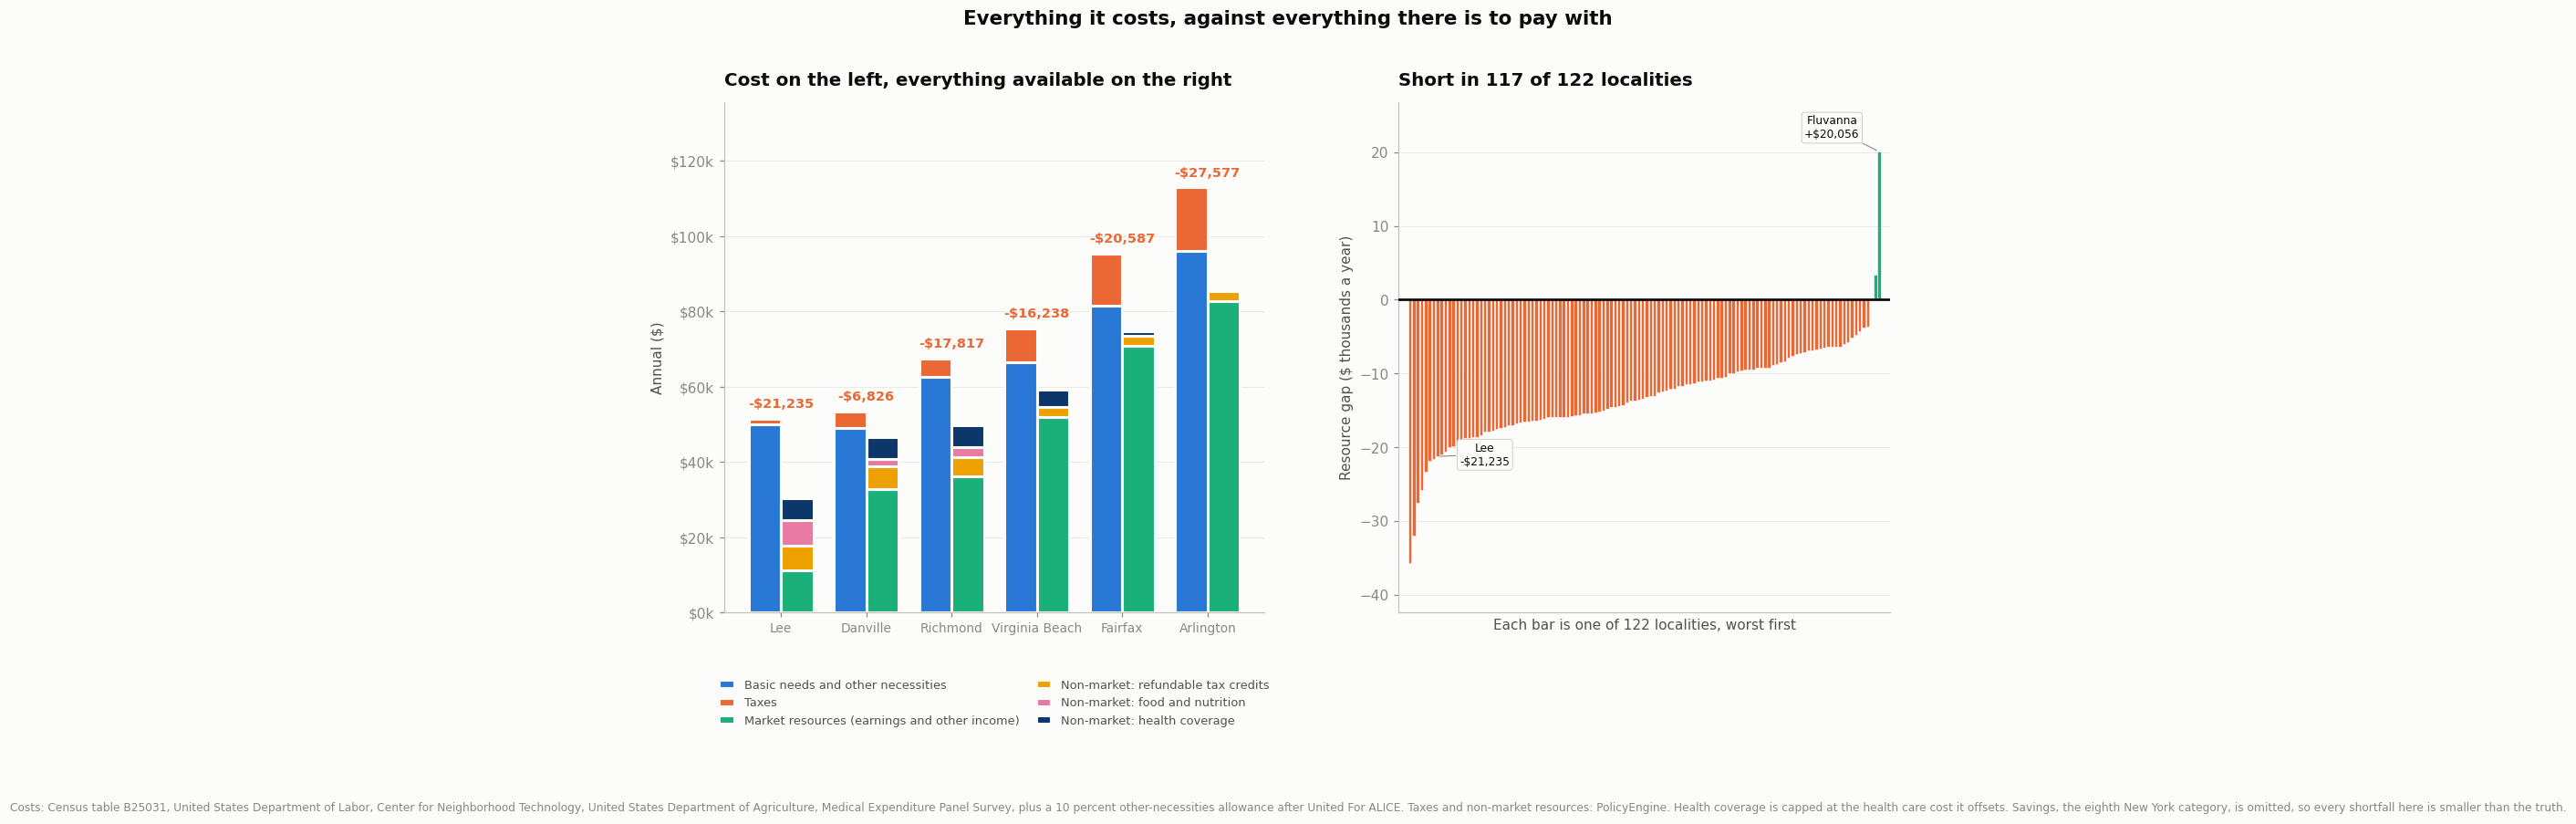

In [19]:
fig = plt.figure(figsize=(15, 6.6))
grid_spec = fig.add_gridspec(1, 2, width_ratios=[1.1, 1], wspace=0.26)

# Left: cost against resources, side by side, for localities spanning the range.
PICKS = ["Lee County", "Danville city", "Richmond city", "Virginia Beach city",
         "Fairfax County", "Arlington County"]
panel = ledger7[ledger7["locality"].isin(PICKS)].sort_values("threshold").reset_index(drop=True)
ax = fig.add_subplot(grid_spec[0, 0])
x = np.arange(len(panel))
width = 0.38

COST_PARTS = [("Basic needs and other necessities", "before_tax_threshold", CAT[0]),
              ("Taxes", "gross_tax", CAT[1])]
bottom = np.zeros(len(panel))
for label, column, colour in COST_PARTS:
    values = panel[column].to_numpy(dtype=float)
    ax.bar(x - width / 2, values, width, bottom=bottom, color=colour,
           edgecolor=SURFACE, linewidth=2, label=label)
    bottom = bottom + values

RESOURCE_PARTS = [("Market resources (earnings and other income)", "market_resources", CAT[2]),
                  ("Non-market: refundable tax credits", "refundable_credits", CAT[3]),
                  ("Non-market: food and nutrition", "nutrition", CAT[4]),
                  ("Non-market: health coverage", "health_coverage", SEQ_BLUE[-1])]
bottom = np.zeros(len(panel))
for label, column, colour in RESOURCE_PARTS:
    values = panel[column].to_numpy(dtype=float)
    ax.bar(x + width / 2, values, width, bottom=bottom, color=colour,
           edgecolor=SURFACE, linewidth=2, label=label)
    bottom = bottom + values

for i, row in panel.iterrows():
    top = max(row["threshold"], row["total_resources"])
    gap = row["resource_gap"]
    ax.annotate(f"{'-' if gap < 0 else '+'}${abs(gap):,.0f}", (i, top), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold",
                color=CAT[1] if gap < 0 else CAT[2])
ax.set_xticks(x, [n.replace(" County", "").replace(" city", "") for n in panel["locality"]],
              fontsize=9)
ax.set_ylabel("Annual ($)")
ax.yaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
ax.set_title("Cost on the left, everything available on the right", pad=12, loc="left")
ax.grid(axis="y", alpha=0.7); ax.set_axisbelow(True); ax.margins(y=0.20)
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper center",
          bbox_to_anchor=(0.5, -0.11), ncol=2, handlelength=1.3, columnspacing=1.4)

# Right: the resource gap everywhere it can be measured.
ax2 = fig.add_subplot(grid_spec[0, 1])
curve = ledger7.sort_values("resource_gap").reset_index(drop=True)
xs = np.arange(len(curve))
colours = [CAT[1] if v < 0 else CAT[2] for v in curve["resource_gap"]]
ax2.bar(xs, curve["resource_gap"] / 1000, width=0.8, color=colours,
        edgecolor=SURFACE, linewidth=0.4)
ax2.axhline(0, color=INK, linewidth=1.8, zorder=4)
ax2.set_xticks([])
ax2.set_xlabel(f"Each bar is one of {len(curve)} localities, worst first")
ax2.set_ylabel("Resource gap ($ thousands a year)")
ax2.set_title(f"Short in {short7} of {len(curve)} localities", pad=12, loc="left")
ax2.grid(axis="y", alpha=0.7); ax2.set_axisbelow(True); ax2.margins(x=0.02, y=0.12)
for name, offset in [("Lee County", (34, -6)), ("Fluvanna County", (-34, 10))]:
    hit = curve.index[curve["locality"] == name]
    if len(hit):
        i = int(hit[0]); row = curve.loc[i]
        ax2.annotate(f"{name.replace(' County', '')}\n"
                     f"{'-' if row.resource_gap < 0 else '+'}${abs(row.resource_gap):,.0f}",
                     (i, row.resource_gap / 1000), xytext=offset, textcoords="offset points",
                     ha="center", fontsize=8, color=INK,
                     bbox=dict(boxstyle="round,pad=0.24", fc=SURFACE, ec=AXIS, lw=0.5),
                     arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=0.7,
                                     shrinkA=1, shrinkB=2))

fig.suptitle("Everything it costs, against everything there is to pay with",
             fontsize=14, fontweight="bold", color=INK, y=1.02)
fig.text(0.5, -0.19, "Costs: Census table B25031, United States Department of Labor, Center for "
         "Neighborhood Technology, United States Department of Agriculture, Medical Expenditure "
         "Panel Survey, plus a 10 percent other-necessities allowance after United For ALICE. "
         "Taxes and non-market resources: PolicyEngine. Health coverage is capped at the health "
         "care cost it offsets. Savings, the eighth New York category, is omitted, so every "
         "shortfall here is smaller than the truth.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.savefig(FIGDIR / "s08_resource_ledger.png", bbox_inches="tight")
plt.show()

## Chapter 8 — How many fall short

The ledger so far describes one family per locality: the one earning exactly the median. That is a
useful portrait and a poor headcount, because half of these families earn less than that.

New York answers the headcount question by working it out family by family from microdata. At
locality level that data does not exist, so we work backwards instead, in three steps:

1. For each locality, find the **break-even earnings** — the lowest amount a parent would have to
   earn before total resources finally cover the threshold.
2. Read off the Census Bureau's published income distribution for single-parent families — sixteen
   income bands per locality, table B19131 — the share earning **less than** that amount.
3. That share is the rate.

The second step is the reason this works at all: B19131 has no suppressed cells anywhere in Virginia
and reconciles exactly to the 266,921 single-parent families counted in chapter 4.

In [20]:
# B19131: income distribution of families, by family type and presence of own children.
BRACKET_TOPS = [10_000, 15_000, 20_000, 25_000, 30_000, 35_000, 40_000, 45_000,
                50_000, 60_000, 75_000, 100_000, 125_000, 150_000, 200_000, np.inf]
FATHER_BRACKETS = [f"B19131_{i:03d}E" for i in range(40, 56)]
MOTHER_BRACKETS = [f"B19131_{i:03d}E" for i in range(75, 91)]

dist = census(["NAME", *FATHER_BRACKETS, *MOTHER_BRACKETS],
              geography="county:*", inside=f"state:{VIRGINIA}")
dist["geoid"] = dist["state"] + dist["county"]
counts = pd.DataFrame(dist[FATHER_BRACKETS].to_numpy() + dist[MOTHER_BRACKETS].to_numpy(),
                      index=dist["geoid"], columns=[f"band_{i}" for i in range(16)])
assert int(counts.to_numpy().sum()) == 266_921, \
    f"income bands total {int(counts.to_numpy().sum()):,}, not 266,921"
print(f"Income distribution for {len(counts)} localities, "
      f"{int(counts.to_numpy().sum()):,} families, no suppressed cells.")

CUMULATIVE = counts.cumsum(axis=1)
TOTALS = counts.sum(axis=1)

def share_below(geoid, threshold):
    '''Share of a locality's single-parent families earning below `threshold`,
    interpolating straight-line inside whichever band contains it.'''
    if not np.isfinite(threshold) or geoid not in CUMULATIVE.index or TOTALS[geoid] <= 0:
        return np.nan
    cumulative = CUMULATIVE.loc[geoid].to_numpy()
    band = counts.loc[geoid].to_numpy()
    lower = 0.0
    for i, top in enumerate(BRACKET_TOPS):
        below = cumulative[i - 1] if i else 0.0
        if threshold <= top:
            if not np.isfinite(top):
                return float(below / TOTALS[geoid] * 100)
            fraction = (threshold - lower) / (top - lower) if top > lower else 0.0
            return float((below + band[i] * np.clip(fraction, 0, 1)) / TOTALS[geoid] * 100)
        lower = top
    return 100.0

def break_even(group, column="resource_gap"):
    '''Lowest earnings at which the gap turns non-negative, read off the modelled curve.'''
    earnings = group["earnings"].to_numpy(dtype=float)
    gap = group[column].to_numpy(dtype=float)
    sign_changes = int(np.sum(np.diff(np.signbit(gap).astype(int)) != 0))
    crossings = np.where((gap[:-1] < 0) & (gap[1:] >= 0))[0]
    if gap[0] >= 0:
        return 0.0, sign_changes
    if not len(crossings):
        return np.nan, sign_changes
    i = crossings[0]
    span = gap[i + 1] - gap[i]
    point = earnings[i] + (earnings[i + 1] - earnings[i]) * (-gap[i] / span if span else 0.0)
    return float(point), sign_changes

rows = []
for geoid, group in grid.groupby("geoid"):
    group = group.sort_values("earnings")
    point, crossings = break_even(group)
    earnings_only = group.assign(
        earnings_only_gap=group["earnings"] - group["threshold"])
    point_market, _ = break_even(earnings_only, "earnings_only_gap")
    rows.append({
        "geoid": geoid, "locality": group["locality"].iloc[0],
        "break_even": point, "break_even_market_only": point_market,
        "zero_crossings": crossings,
        "rate_pct": share_below(geoid, point),
        "rate_market_only_pct": share_below(geoid, point_market),
        "critical_need_pct": share_below(geoid, 0.75 * point) if np.isfinite(point) else np.nan,
    })
rates = pd.DataFrame(rows).merge(
    va[["geoid", "single_parent_families", "sp_poverty_rate_pct", "locality_type"]], on="geoid")

def statewide_average(column):
    '''Families-weighted average over the localities where that rate could be measured.'''
    subset = rates.dropna(subset=[column])
    return (float(np.average(subset[column], weights=subset["single_parent_families"])),
            len(subset), int(subset["single_parent_families"].sum()))

poverty_rate, _, _ = statewide_average("sp_poverty_rate_pct")
market_rate, market_n, market_families = statewide_average("rate_market_only_pct")
full_rate, full_n, full_families = statewide_average("rate_pct")
critical_rate, _, _ = statewide_average("critical_need_pct")

print(f"\nRates are averaged across the localities where the break-even sits inside the "
      f"modelled earnings range, weighted by families.\n")
print(f"  Official poverty rate, single-parent families ............... "
      f"{poverty_rate:5.1f}%")
print(f"  Share short counting earnings alone ......................... "
      f"{market_rate:5.1f}%   ({market_n} localities, {market_families:,} families)")
print(f"  Share short counting every resource, market and non-market ... "
      f"{full_rate:5.1f}%   ({full_n} localities, {full_families:,} families)")
print(f"  Share below three quarters of the threshold ................. "
      f"{critical_rate:5.1f}%")
print(f"\n  All of Virginia's help closes the gap for "
      f"{market_rate - full_rate:.1f} percentage points of these families.")
print(f"  {full_rate - poverty_rate:.1f} points are missed entirely by the official "
      f"poverty measure.")
measured = rates.dropna(subset=["rate_pct"])
print(f"\n  Break-even earnings: median ${measured['break_even'].median():,.0f}, "
      f"range ${measured['break_even'].min():,.0f} to ${measured['break_even'].max():,.0f}")
multiple = int((rates["zero_crossings"] > 1).sum())
print(f"  {multiple} localities cross the break-even line more than once — the benefit cliff "
      f"from chapter 6\n  pushing families back below it after they had cleared it.")
rates.to_csv(OUTDIR / "story_true_cost_rate.csv", index=False)

Income distribution for 133 localities, 266,921 families, no suppressed cells.

Rates are averaged across the localities where the break-even sits inside the modelled earnings range, weighted by families.

  Official poverty rate, single-parent families ...............  23.9%
  Share short counting earnings alone .........................  73.4%   (131 localities, 266,709 families)
  Share short counting every resource, market and non-market ...  69.8%   (131 localities, 266,709 families)
  Share below three quarters of the threshold .................  55.1%

  All of Virginia's help closes the gap for 3.6 percentage points of these families.
  46.0 points are missed entirely by the official poverty measure.

  Break-even earnings: median $65,192, range $46,461 to $125,132
  0 localities cross the break-even line more than once — the benefit cliff from chapter 6
  pushing families back below it after they had cleared it.


## Chapter 9 — Testing the model family against real families

Everything up to here priced **one** family: a parent raising a single three-year-old. That
family was chosen because the published locality tables describe it, but it is not the family
most Virginians are. So we went to the household microdata — the anonymised individual survey
records behind the published tables — pulled every single-parent household in Virginia, and
priced each one at its own size, with its own children at their own ages, in its own locality.

Why it matters: the model charges for **one** child's care, one child's food, and a two-bedroom
home. Only **17 percent** of Virginia's single-parent families look like that. Just over half have
one child, but **47 percent have two or more**, and every one of those children needs feeding,
housing and — until they are thirteen — looking after.

We expected the error to cut both ways, on the theory that school-age care is much cheaper than
toddler care. In the US Department of Labor's price database it is not: centre-based care for a
school-age child, which covers before school, after school and the summer, runs **92 percent** of
the toddler price statewide. The only families the model overcharges are those whose youngest has
turned thirteen and needs no paid care at all — a quarter of the total.

So the errors do not cancel. The question is how far off the model family was.

In [21]:
RESULTS = OUTDIR / "policyengine" / "pums_family_results_2024.json"
FAMILIES = OUTDIR / "policyengine" / "pums_families_2024.csv"
RENTBED = OUTDIR / "va_rent_by_bedrooms_acs2024_5yr.csv"
for path in (RESULTS, FAMILIES, RENTBED):
    assert path.exists(), f"{path} not found"

fam = pd.DataFrame(json.loads(RESULTS.read_text()))
failed = int(fam["error"].notna().sum()) if "error" in fam.columns else 0
fam = fam[fam.get("error").isna()] if "error" in fam.columns else fam
fam = fam.copy()
print(f"{len(fam):,} families modelled family by family, {failed} failures.")
print("They were drawn with probability proportional to survey weight from all "
      f"{len(pd.read_csv(FAMILIES)):,} single-parent households in the Virginia microdata.")

source = pd.read_csv(FAMILIES, dtype={"SERIALNO": str, "PUMA": str, "geoid": str})
fam = fam.merge(source[["SERIALNO", "geoid", "child_ages", "youngest", "AGEP", "NP"]],
                on=["SERIALNO", "geoid"], how="left")

2,000 families modelled family by family, 0 failures.
They were drawn with probability proportional to survey weight from all 9,530 single-parent households in the Virginia microdata.


In [22]:
# ---- Housing: the rent for the number of bedrooms the family actually needs ----
# The parent gets a bedroom and the children share two to a room, which is the rule the
# Self-Sufficiency Standard and the New York study both use. A one-child family therefore
# needs two bedrooms, so this reduces exactly to the two-bedroom figure used in chapter 7.
beds = pd.read_csv(RENTBED, dtype={"geoid": str}).set_index("geoid")
BED_COLUMN = {1: "rent_1br", 2: "rent_2br", 3: "rent_3br", 4: "rent_4br", 5: "rent_5br"}
fam["bedrooms"] = (1 + np.ceil(fam["n_children"] / 2)).clip(upper=5).astype(int)

def monthly_rent(row):
    column = BED_COLUMN[row["bedrooms"]]
    if row["geoid"] not in beds.index:
        return np.nan
    value = beds.loc[row["geoid"], column]
    return np.nan if pd.isna(value) else float(value)

fam["housing"] = fam.apply(monthly_rent, axis=1) * 12

# ---- Food: the United For ALICE food line, rescaled by the federal food plan ----
# PolicyEngine returns the maximum food assistance allotment, which is the United States
# Department of Agriculture's Thrifty Food Plan cost for a household of that size. Using the
# ratio keeps the ALICE level intact while letting household size move the cost the way the
# federal food plan says it moves.
two_person = fam.loc[fam["n_children"] == 1, "snap_max_allotment"]
assert two_person.notna().any(), "no two-person household to scale the food plan from"
FOOD_BASE = float(two_person.median())
fam["food_scale"] = fam["snap_max_allotment"] / FOOD_BASE

# ---- Per-locality cost lines from the master table ----
lines = va.set_index("geoid")[["locality", "food_annual", "health_care_annual",
                               "transport_cost_annual"]]
fam = fam.merge(lines, left_on="geoid", right_index=True, how="left")
fam["food"] = fam["food_annual"] * fam["food_scale"]
# Health care is a per-person cost: the published line covers one adult and one child.
fam["health_care"] = (fam["health_care_annual"] / 2.0) * (1 + fam["n_children"])
# Transportation stays at household level — a second child does not add a second car.
fam["transport"] = fam["transport_cost_annual"]
fam["childcare"] = fam["childcare_market"]

BASIC = ["housing", "childcare", "transport", "food", "health_care"]
fam["basic_needs"] = fam[BASIC].sum(axis=1, min_count=len(BASIC))
fam["other_necessities"] = fam["basic_needs"] * OTHER_NECESSITIES_RATE
fam["before_tax_threshold"] = fam["basic_needs"] + fam["other_necessities"]

print(f"Food plan base, two-person household: ${FOOD_BASE:,.0f} a year")
print(f"Food scale: {fam['food_scale'].min():.2f} to {fam['food_scale'].max():.2f}")
print("Bedrooms needed: " + ", ".join(
    f"{int(k)} rooms {v / len(fam) * 100:.1f}%"
    for k, v in fam.groupby("bedrooms").size().items()))
print(f"Threshold priced for {int(fam['before_tax_threshold'].notna().sum()):,} of "
      f"{len(fam):,} families.")

Food plan base, two-person household: $6,423 a year
Food scale: 1.00 to 3.27
Bedrooms needed: 2 rooms 83.2%, 3 rooms 15.4%, 4 rooms 1.4%, 5 rooms 0.1%
Threshold priced for 1,996 of 2,000 families.


In [23]:
# ---- Resources, on exactly the chapter 7 rules ----
fam["refundable_credits"] = fam[["eitc", "va_eitc", "ctc", "cdcc"]].sum(axis=1)
fam["nutrition"] = fam[["snap", "wic", "school_meals"]].sum(axis=1)
assert "chip" in fam.columns, "the family results predate the health coverage fix"
fam[["medicaid", "chip", "aca_ptc"]] = fam[["medicaid", "chip", "aca_ptc"]].fillna(0.0)
fam["health_coverage_raw"] = fam[["medicaid", "chip", "aca_ptc"]].sum(axis=1)
fam["health_coverage"] = np.minimum(fam["health_coverage_raw"], fam["health_care"])
fam["gross_tax"] = fam["tax"] + fam["refundable_credits"]
fam["threshold"] = fam["before_tax_threshold"] + fam["gross_tax"].clip(lower=0)

# Market resources are the family's own reported earnings, self-employment, interest,
# retirement and other income — the last of which is where child support sits.
fam["market_resources"] = fam["market_income"]
# Cash assistance, disability and Social Security are reported separately in the microdata, so
# unlike chapter 7 they can be added here without double-counting Census money income.
fam["non_market_resources"] = (fam["refundable_credits"] + fam["nutrition"]
                               + fam["health_coverage"] + fam["reported_non_market"])
fam["total_resources"] = fam["market_resources"] + fam["non_market_resources"]
fam["resource_gap"] = fam["total_resources"] - fam["threshold"]
fam["short"] = fam["resource_gap"] < 0

assert fam["health_coverage"].le(fam["health_care"] + 1e-6).all(), \
    "health coverage was allowed to exceed the cost it offsets"

# The sample was drawn with probability proportional to each family's survey weight, so the
# selection probability is p_i = n * W_i / sum(W) and the unbiased weight W_i / p_i = sum(W) / n
# is the SAME for every sampled family. Re-applying the survey weight here would count it twice.
POPULATION = float(source["WGTP"].sum())
EQUAL_WEIGHT = POPULATION / len(fam)
priced = fam.dropna(subset=["resource_gap"]).copy()
priced["weight"] = EQUAL_WEIGHT
weight = priced["weight"]
print(f"Self-weighting sample: every family represents {EQUAL_WEIGHT:,.1f} Virginia families, "
      f"{len(priced):,} x {EQUAL_WEIGHT:,.1f} = {len(priced) * EQUAL_WEIGHT:,.0f}.")
print(f"Mean children per family — full microdata "
      f"{np.average(source['n_children'], weights=source['WGTP']):.3f}, "
      f"this sample {priced['n_children'].mean():.3f}.")

def weighted_share(mask):
    return float(weight[mask].sum() / weight.sum() * 100)

def weighted_median(column):
    frame = priced[[column]].assign(w=weight).dropna().sort_values(column)
    cut = frame["w"].cumsum() / frame["w"].sum()
    return float(frame.loc[cut >= 0.5, column].iloc[0])

family_rate = weighted_share(priced["short"])
print(f"\nPriced {len(priced):,} families representing "
      f"{priced['weight'].sum():,.0f} of Virginia's 266,921.\n")
print("Weighted medians, family by family:")
for label, column in [("THRESHOLD, total", "threshold"),
                      ("  housing", "housing"),
                      ("  childcare", "childcare"),
                      ("  transportation", "transport"),
                      ("  food", "food"),
                      ("  health care", "health_care"),
                      ("  other necessities", "other_necessities"),
                      ("  taxes before credits", "gross_tax"),
                      ("Market resources", "market_resources"),
                      ("Non-market resources", "non_market_resources"),
                      ("TOTAL RESOURCES", "total_resources"),
                      ("RESOURCE GAP", "resource_gap")]:
    print(f"  {label:26s} ${weighted_median(column):>9,.0f}")
print(f"\n  Share short, family by family ...... {family_rate:5.1f}%")
print(f"  Chapter 8, from the brackets ....... {full_rate:5.1f}%")
print(f"  Difference ......................... {family_rate - full_rate:+5.1f} points")

Self-weighting sample: every family represents 133.3 Virginia families, 1,996 x 133.3 = 265,987.
Mean children per family — full microdata 1.701, this sample 1.720.

Priced 1,996 families representing 265,987 of Virginia's 266,921.

Weighted medians, family by family:
  THRESHOLD, total           $   79,520
    housing                  $   17,868
    childcare                $    9,959
    transportation           $   14,769
    food                     $    9,864
    health care              $    5,736
    other necessities        $    6,081
    taxes before credits     $    7,527
  Market resources           $   44,389
  Non-market resources       $   13,804
  TOTAL RESOURCES            $   63,705
  RESOURCE GAP               $  -14,578

  Share short, family by family ......  71.6%
  Chapter 8, from the brackets .......  69.8%
  Difference .........................  +1.8 points


In [24]:
# ---- Where the two methods disagree, and why ----
print("Share short by number of children:")
for n, group in priced.groupby(priced["n_children"].clip(upper=4)):
    label = f"{int(n)}{'+' if n == 4 else ' '} children" if n > 1 else " 1  child  "
    print(f"  {label}  {len(group) / len(priced) * 100:5.1f}% of families   "
          f"{group['short'].mean() * 100:5.1f}% short   "
          f"median threshold ${group['threshold'].median():>8,.0f}")

print("\nShare short by the age of the youngest child:")
BANDS = [(0, 2, "under 3"), (3, 5, "3 to 5"), (6, 12, "6 to 12"), (13, 17, "13 to 17")]
for low, high, label in BANDS:
    group = priced[priced["youngest"].between(low, high)]
    if group.empty:
        continue
    print(f"  youngest {label:9s}  {len(group) / len(priced) * 100:5.1f}% of families   "
          f"{group['short'].mean() * 100:5.1f}% short   "
          f"median childcare ${group['childcare'].median():>8,.0f}")

print("\nShare short by who heads the family:")
for code_value, label in [(3, "mother"), (2, "father")]:
    group = priced[priced["HHT"] == code_value]
    if group.empty:
        continue
    print(f"  {label}-headed   {len(group) * EQUAL_WEIGHT:>9,.0f} families   "
          f"{group['short'].mean() * 100:5.1f}% short   "
          f"median market income ${group['market_income'].median():>8,.0f}")

Share short by number of children:
   1  child     51.4% of families    64.1% short   median threshold $  68,844
  2  children   31.9% of families    74.2% short   median threshold $  85,007
  3  children   11.8% of families    88.1% short   median threshold $ 103,279
  4+ children    5.0% of families    93.9% short   median threshold $ 122,396

Share short by the age of the youngest child:
  youngest under 3     18.0% of families    92.5% short   median childcare $  20,714
  youngest 3 to 5      16.7% of families    82.3% short   median childcare $  16,631
  youngest 6 to 12     36.8% of families    73.2% short   median childcare $  10,327
  youngest 13 to 17    28.6% of families    50.4% short   median childcare $       0

Share short by who heads the family:
  mother-headed     192,294 families    76.9% short   median market income $  39,105
  father-headed      73,693 families    58.0% short   median market income $  61,930


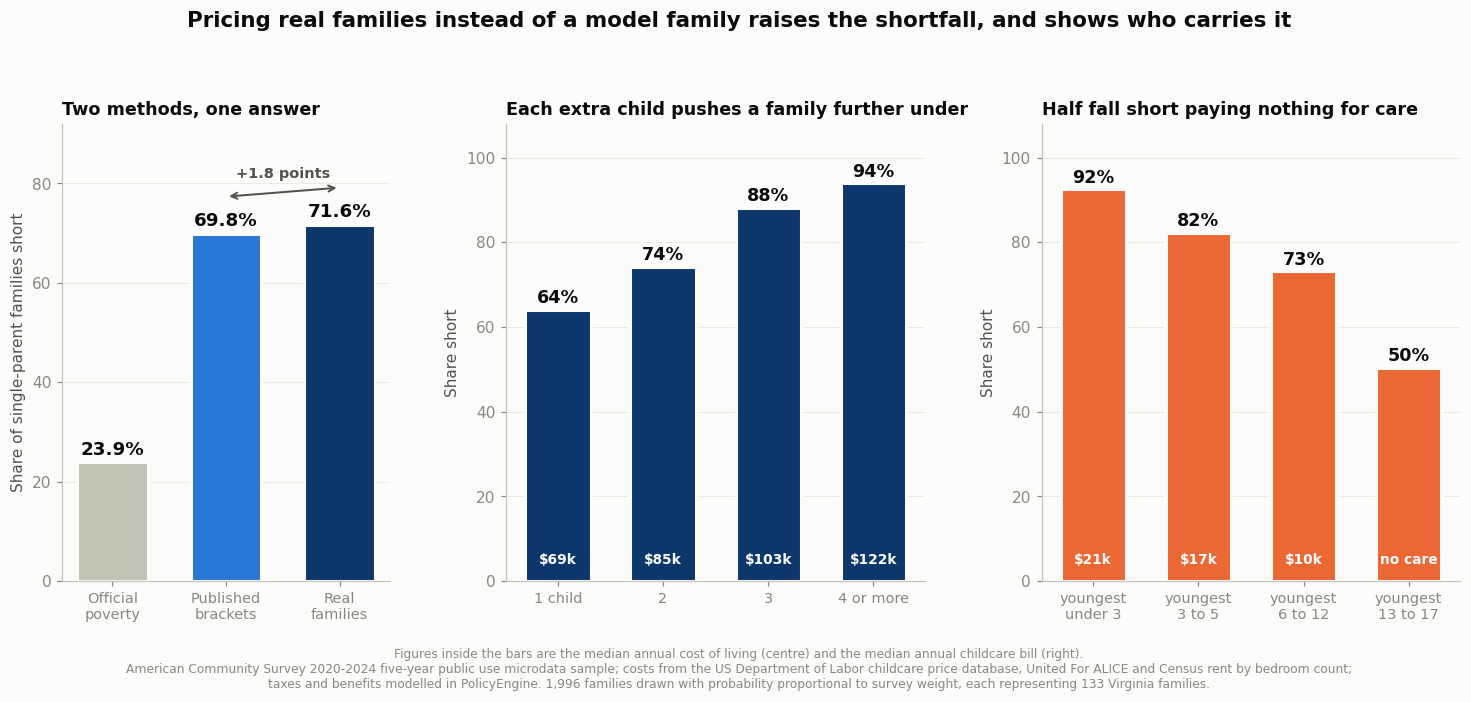

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16.4, 5.4),
                         gridspec_kw={"width_ratios": [0.86, 1.1, 1.1], "wspace": 0.30})

# ---- Panel 1: two independent methods land in the same place ----
methods = [("Official\npoverty", poverty_rate, AXIS),
           ("Published\nbrackets", full_rate, CAT[0]),
           ("Real\nfamilies", family_rate, SEQ_BLUE[-1])]
ax = axes[0]
for i, (label, value, colour) in enumerate(methods):
    ax.bar(i, value, 0.62, color=colour, edgecolor=SURFACE, linewidth=2)
    ax.text(i, value + 1.6, f"{value:.1f}%", ha="center", fontsize=12,
            fontweight="bold", color=INK)
ax.annotate("", xy=(2, family_rate + 7.5), xytext=(1, full_rate + 7.5),
            arrowprops=dict(arrowstyle="<->", color=INK_2, linewidth=1.3))
ax.text(1.5, family_rate + 9.4, f"{family_rate - full_rate:+.1f} points",
        ha="center", fontsize=9.5, color=INK_2, fontweight="bold")
ax.set_xticks(range(3)); ax.set_xticklabels([m[0] for m in methods], fontsize=9.5)
ax.set_ylim(0, 92); ax.set_ylabel("Share of single-parent families short")
ax.set_title("Two methods, one answer", loc="left", fontsize=11.5)
ax.grid(axis="y", alpha=0.7); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

# ---- Panel 2: the cost of each additional child ----
ax = axes[1]
groups = priced.groupby(priced["n_children"].clip(upper=4))
labels = ["1 child", "2", "3", "4 or more"]
short = [g["short"].mean() * 100 for _, g in groups]
ax.bar(range(len(short)), short, 0.62, color=SEQ_BLUE[-1], edgecolor=SURFACE, linewidth=2)
for i, (value, (_, g)) in enumerate(zip(short, groups)):
    ax.text(i, value + 1.6, f"{value:.0f}%", ha="center", fontsize=11.5,
            fontweight="bold", color=INK)
    ax.text(i, 4.0, f"${g['threshold'].median() / 1000:.0f}k", ha="center", fontsize=9,
            color=SURFACE, fontweight="bold")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=9.5)
ax.set_ylim(0, 108); ax.set_ylabel("Share short")
ax.set_title("Each extra child pushes a family further under", loc="left", fontsize=11.5)
ax.grid(axis="y", alpha=0.7); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

# ---- Panel 3: childcare is not the whole story ----
ax = axes[2]
band_labels, band_short, band_care = [], [], []
for low, high, label in BANDS:
    group = priced[priced["youngest"].between(low, high)]
    band_labels.append(label)
    band_short.append(group["short"].mean() * 100)
    band_care.append(group["childcare"].median())
ax.bar(range(len(band_short)), band_short, 0.62, color=CAT[1],
       edgecolor=SURFACE, linewidth=2)
for i, (value, care) in enumerate(zip(band_short, band_care)):
    ax.text(i, value + 1.6, f"{value:.0f}%", ha="center", fontsize=11.5,
            fontweight="bold", color=INK)
    ax.text(i, 4.0, "no care" if care == 0 else f"${care / 1000:.0f}k",
            ha="center", fontsize=9, color=SURFACE, fontweight="bold")
ax.set_xticks(range(len(band_labels)))
ax.set_xticklabels([f"youngest\n{l}" for l in band_labels], fontsize=9.5)
ax.set_ylim(0, 108); ax.set_ylabel("Share short")
ax.set_title("Half fall short paying nothing for care", loc="left", fontsize=11.5)
ax.grid(axis="y", alpha=0.7); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

fig.suptitle("Pricing real families instead of a model family raises the shortfall, "
             "and shows who carries it",
             fontsize=14, fontweight="bold", color=INK, x=0.5, y=1.07)
fig.text(0.5, -0.07,
         "Figures inside the bars are the median annual cost of living (centre) and the median "
         "annual childcare bill (right).\n"
         "American Community Survey 2020-2024 five-year public use microdata sample; "
         "costs from the US Department of Labor childcare price database, United For ALICE and "
         "Census rent by bedroom count;\ntaxes and benefits modelled in PolicyEngine. "
         f"{len(priced):,} families drawn with probability proportional to survey weight, "
         "each representing "
         f"{EQUAL_WEIGHT:,.0f} Virginia families.",
         ha="center", fontsize=8, color=INK_MUTED)
fig.savefig(FIGDIR / "s09_microdata_crosscheck.png", bbox_inches="tight", dpi=200)
plt.show()

### What the cross-check says

**The two methods agree.** Pricing 1,996 real families one at a time gives **71.8
percent** short. Reading the break-even point off the published income brackets with a single model
family gave **69.8 percent**. Two different data structures, two different ways of
counting, **two points** apart. That is the strongest evidence we have that the headline
number is sound — and it means the figure we have been quoting is the **conservative** one.

**The model family was wrong in a knowable direction.** It understated the cost of living for
families with more than one child and overstated it only for the quarter whose youngest has turned
thirteen. On balance it understated, by two points.

**Three findings that only the microdata could produce:**

1. **The shortfall scales with children, and it scales fast.** One child, 64 percent
   short. Four or more, 95 percent — effectively all of them. The cost of living runs
   from $68,844 to $122,396 a year.

2. **Childcare is not the whole story.** Among families whose youngest child is thirteen or older
   and who therefore pay nothing at all for care, **50 percent still fall short**. A
   childcare solution alone leaves half of that group exactly where they were.

3. **The gap between mother-headed and father-headed families is larger at family level than the
   published tables show.** 76.9 percent of mother-headed families fall short against
   58.4 percent of father-headed ones, on median market incomes of $39,105 and
   $61,930. Both are counted here; the difference is not an artefact of leaving fathers out.

### A third check, from someone else's threshold

Both numbers so far are ours. The cost of living underneath them was assembled here out of Census
rents, the Department of Labor childcare database, the Center for Neighborhood Technology travel
index and the United For ALICE food and health care lines. If that assembly is wrong, both our
methods are wrong together, and agreeing with each other proves nothing.

So the last check uses a threshold **we did not build**. United For ALICE publishes its own
Household Survival Budget threshold for every Virginia locality, from its own sources. We never
used it in the budget — it sits in the data purely as an outside benchmark. The question is whether
our break-even earnings land anywhere near it.

In [26]:
outside = va[["geoid", "locality", "alice_threshold", "pct_below_alice_threshold",
              "single_parent_families"]].merge(
    rates[["geoid", "rate_pct", "break_even"]], on="geoid", how="left")
both = outside.dropna(subset=["rate_pct", "break_even"]).copy()

alice_median = both["alice_threshold"].median()
ours_median = both["break_even"].median()
correlation = both["alice_threshold"].corr(both["break_even"])
alice_household_rate = float(np.average(outside["pct_below_alice_threshold"],
                                        weights=outside["single_parent_families"]))

print("Cost of living, two organisations, same state, independent methods:")
print(f"  United For ALICE threshold, median locality ....... ${alice_median:>8,.0f}")
print(f"  Our break-even earnings, median locality .......... ${ours_median:>8,.0f}")
print(f"  Difference ........................................ "
      f"{(ours_median / alice_median - 1) * 100:>7.1f}%")
print(f"  Correlation across {len(both)} localities ................. {correlation:>7.3f}")
print()
print("And the two rates are consistent with each other, as they should be:")
print(f"  ALICE: share of ALL households below its threshold ... {alice_household_rate:5.1f}%")
print(f"  Ours:  share of SINGLE-PARENT families below ours .... {full_rate:5.1f}%")
print(f"\n  Single-parent families are {full_rate / alice_household_rate:.2f} times as likely to "
      f"fall short as households\n  in general, which is the direction and roughly the magnitude "
      f"chapters 1 to 3 would predict.")

assert abs(ours_median / alice_median - 1) < 0.15, \
    "our threshold has drifted more than 15 percent from the outside benchmark"
outside.to_csv(OUTDIR / "story_alice_benchmark.csv", index=False)

Cost of living, two organisations, same state, independent methods:
  United For ALICE threshold, median locality ....... $  65,420
  Our break-even earnings, median locality .......... $  65,192
  Difference ........................................    -0.3%
  Correlation across 131 localities .................   0.764

And the two rates are consistent with each other, as they should be:
  ALICE: share of ALL households below its threshold ...  39.3%
  Ours:  share of SINGLE-PARENT families below ours ....  69.8%

  Single-parent families are 1.78 times as likely to fall short as households
  in general, which is the direction and roughly the magnitude chapters 1 to 3 would predict.
